In [1]:
# Parámetro del notebook: el tipo de crisis a visualizar (ver sección 2).
# Papermill sustituye esta celda (etiqueta 'parameters') al lanzarlo desde 03_ejecutar_visualizaciones.ipynb
TIPO_CRISIS = 'absz'

In [2]:
# Parameters
TIPO_CRISIS = "fnsz"


In [3]:
# Recarga automática: si cambia un módulo de tfm_comun, se vuelve a cargar solo (sin reiniciar el kernel)
%load_ext autoreload
%autoreload 2

# Título del notebook: nombre y abreviatura del tipo de crisis
import sys
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tfm_comun').is_dir())))
# Vuelve a leer tfm_comun del disco cada vez que se ejecuta esta celda (por si ha cambiado), sin reiniciar el kernel
for modulo in [m for m in list(sys.modules) if m == 'tfm_comun' or m.startswith('tfm_comun.')]:
    del sys.modules[modulo]
from IPython.display import display, Markdown
from tfm_comun.dataset.tipos_crisis import info_tipo
from tfm_comun.dataset.tipos_crisis import grupo
from tfm_comun.visual.iconos import ICONO_ETIQUETA, ICONO_GRUPO
from tfm_comun.visual.ficheros import mostrar_fichero

display(Markdown(f'# Crisis {info_tipo(TIPO_CRISIS)["nombre"]}: {ICONO_ETIQUETA[TIPO_CRISIS]} `{TIPO_CRISIS}` '
                 f'({ICONO_GRUPO[grupo(TIPO_CRISIS)]})\n'
                 f'### Visualización de una crisis real de TUSZ'))

# Crisis focal no específica: 🟥 `fnsz` (♦️)
### Visualización de una crisis real de TUSZ

> 🧭 **En 30 segundos**
> - **Para qué:** ver por primera vez la **señal EEG** de una crisis real del tipo elegido y entender qué tendrá que aprender el modelo.
> - **Entra:** un EDF de 🔵 train (elegido solo) + `crisis.csv` → **Sale:** unas 23 figuras y `crisis_ejemplo.csv` en `outputs/fase_01/03_visualizacion/<tipo>/`
> - **Idea clave:** la crisis se ve clarísima (amplitud y frecuencia); el preictal, no: detectar es fácil, predecir es lo difícil. Y se puede estimar **dónde arranca** dentro del cerebro.

Último paso de la **Fase 1 (exploración de datos)**. Los notebooks 01 y 02 trabajaron con tablas; aquí abrimos por primera vez la **señal EEG** de un fichero real y vemos cómo es una crisis.

Objetivos:

1. Leer un EDF con **MNE** y entender qué canales trae.
2. Pasar las anotaciones `.csv` / `.csv_bi` a la señal.
3. Construir el **montaje TCP de 22 canales** (el que usaremos en todo el TFM) y probarlo en un fichero antes de hacerlo con los 8.140.
4. Ver la crisis: señal, frecuencia característica, espectro y espectrograma.
5. Ver los minutos **antes** de la crisis: lo que tendrá que aprender el modelo de predicción.
6. Ver **dónde se origina** la crisis: los canales que arrancan primero, el mapa de la cabeza y el cerebro en 3D.

| Notebook | Qué hace | Salidas |
|---|---|---|
| `01_inventario_tusz.ipynb` | Recorre TUSZ y construye las tablas | `outputs/fase_01/01_inventario/` |
| `02_eda_tusz.ipynb` | Analiza las tablas | `outputs/fase_01/02_eda/` |
| `03_ejecutar_visualizaciones.ipynb` | Lanzador: ejecuta el 03v para cada tipo de crisis | `outputs/fase_01/03_visualizacion/` |
| `03v_visualizacion_crisis.ipynb` | Abre un EDF y visualiza una crisis (este notebook) | `outputs/fase_01/03_visualizacion/<tipo>/` |

Todos están en la carpeta `fase_01/`, y sus resultados en `outputs/fase_01/`.

**Requisito**: haber ejecutado antes `01_inventario_tusz.ipynb` (usamos `crisis.csv` para elegir la crisis).

### Dos ideas antes de empezar

**🧠 El montaje TCP.** El EDF guarda cada electrodo medido contra una **referencia** común (las orejas o la media de todos los electrodos). El montaje **TCP** (*Temporal Central Parasagittal*) transforma esas señales en **22 canales bipolares**: cada canal es la **resta de dos electrodos vecinos** (por ejemplo `FP1-F7`). Lo usamos por tres motivos:

1. Es el montaje en el que los neurólogos **anotaron las crisis de TUSZ**: las etiquetas del `.csv` van canal a canal en TCP.
2. **Unifica los ficheros**: al restar dos electrodos la referencia se cancela, así que da igual cómo se grabó el EDF; todos acaban con los mismos canales.
3. Resalta lo que pasa **en cada zona** de la cabeza y quita lo que es común a todos los electrodos (ruido de la referencia).

Se ve en detalle en la sección 7.

**El tipo de crisis.** El notebook sirve para **cualquier tipo de crisis**. Tiene un único parámetro, `TIPO_CRISIS` (sección 2), y dos formas de usarlo:

1. **A mano**: cambias `TIPO_CRISIS` y lo ejecutas, como cualquier notebook.
2. **Con el lanzador** `03_ejecutar_visualizaciones.ipynb`: ejecuta este notebook con **papermill** para todos los tipos y deja una copia ejecutada en `outputs/fase_01/03_visualizacion/<tipo>/`, junto a sus figuras.

Qué es cada tipo y cómo se ve en el EEG está en `tfm_comun/dataset/tipos_crisis.py`, y se muestra en la sección 2.

## 1. Importación de librerías

**Requisitos.** Lo primero es comprobar que están instaladas todas las librerías que usa el notebook (`tfm_comun/entorno/requisitos.py`). Sale una tabla con cada una: ✅ instalada (con su versión) o 🆕 recién instalada. **Lo que falte se instala solo** con pip, en el mismo Python del notebook (el del `.venv`). Si no se pudiera instalar: ❌ si es obligatoria (el notebook se para) o 🔴 si es opcional (solo la usa una parte, como el 3D de la sección 14, que se saltará).

- `mne`: librería de referencia para EEG en Python [8]. Lee el EDF, construye el montaje TCP, filtra y calcula espectros.
- `scipy.signal`: espectro de Welch y espectrograma.
- `tfm_comun`: utilidades del TFM, un módulo por responsabilidad, ordenadas en carpetas por funcionalidad. En este notebook se estrenan:
  - `entorno/rutas.py`: dónde están el dataset y las salidas (lo usarán todos los notebooks).
  - `dataset/canales.py`: qué es cada canal del EDF (tipo, región de la cabeza, referencia).
  - `dataset/edf.py`, `dataset/anotaciones.py`, `senal/montaje.py`: leer el EDF, leer las crisis y construir el montaje TCP.
  - `senal/bandas.py`: bandas de frecuencia del EEG.
  - `visual/cabeza.py`: dibujo de la cabeza con los electrodos.
  - `dataset/tipos_crisis.py`: qué es cada tipo de crisis y cómo se ve en el EEG.
  - `senal/fuentes.py` y `dataset/regiones_cerebro.py`: dónde se origina la crisis dentro del cerebro (sección 14).
  - `visual/inicio_crisis.py`, `visual/cerebro.py` y `visual/tipografia.py`: las figuras de la sección 14.
- `pyvista` y `pyvistaqt` (solo sección 14): dibujan el cerebro en 3D. Si no están instalados, el notebook funciona igual y se salta las figuras 3D.

Mostramos la versión de cada librería para que los resultados se puedan reproducir.

Las primeras líneas añaden la carpeta `ALMA` al path de Python: el notebook está en `fase_01/` y `tfm_comun` un nivel por encima.

In [4]:
import sys
from pathlib import Path

# tfm_comun está en ALMA, por encima de la carpeta de la fase: lo añadimos al path de Python
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tfm_comun').is_dir())))

# Antes de nada: ¿está instalado todo lo que necesita el notebook?
from tfm_comun.entorno.requisitos import comprobar_requisitos, REQUISITOS_03V
disponibles = comprobar_requisitos(REQUISITOS_03V)

import json
import time

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import scipy
from scipy import signal
from IPython.display import display, Markdown
import mne

from tfm_comun.entorno.rutas import RUTA_EDF, RUTA_OUTPUTS_FASE_01, carpeta_resultados, buscar_edf
from tfm_comun.visual.iconos import con_icono, tabla_con_iconos, ICONO_TIPO_CANAL, ICONO_REGION
from tfm_comun.visual.colores import (COLORES_ETIQUETA, COLORES_PERIODO, COLORES_SPLIT, COLORES_TIPO_CANAL,
                               COLORES_REGION, COLORES_BANDA, ESTILOS_LADO)
from tfm_comun.visual.ejes import eje_log_legible
from tfm_comun.visual.numeros import numero_legible, duracion_legible
from tfm_comun.dataset.canales import (REFERENCIAS, MONTAJES_TUSZ, REGIONES, DESCRIPCION_TIPO,
                               referencia_canal, region_electrodo, lado_electrodo, descripcion_canal)
from tfm_comun.dataset.edf import leer_edf_tusz
from tfm_comun.dataset.anotaciones import leer_anotaciones, crisis_del_fichero, a_anotaciones_mne
from tfm_comun.senal.montaje import montaje_tcp, PARES_TCP, CADENAS_TCP
from tfm_comun.senal.bandas import BANDAS_HZ, DESCRIPCION_BANDA
from tfm_comun.visual.cabeza import dibujar_contorno, dibujar_electrodos, dibujar_pares, POSICIONES_1020
from tfm_comun.dataset.tipos_crisis import info_tipo
from tfm_comun.prediccion.umbrales import umbral_leadin_s, sph_s, margen_postictal_s
from tfm_comun.visual.esquemas import dibujar_esquema_periodos
from tfm_comun.entorno.versiones import mostrar_versiones

versiones = mostrar_versiones(np, pd, matplotlib, scipy, mne)

,estado,versión,para qué
librería,,,
numpy,✅,2.5.4,cálculo con matrices
pandas,✅,3.0.6,tablas
matplotlib,✅,3.11.2,figuras
scipy,✅,1.18.1,espectros (Welch) y espectrogramas
mne,✅,1.13.2,"leer el EDF, montaje, filtros y localización de fuentes"
nibabel,✅,5.4.2,leer el cerebro plantilla y su atlas (sección 14)
pyvista,✅,0.49.2,dibujar el cerebro en 3D (sección 14)
pyvistaqt,✅,0.13.1,motor 3D de MNE (sección 14)
pyqt6,✅,6.12.0,ventanas del 3D (sección 14)


Todo lo necesario está instalado.


Python      3.14.0
numpy       2.5.4
pandas      3.0.6
matplotlib  3.11.2
scipy       1.18.1
mne         1.13.2


## 2. Configuración

- `TIPO_CRISIS`: **el tipo de crisis que vamos a visualizar** (`'absz'`, `'tnsz'`, `'fnsz'`...). Está sola en la **primera celda del notebook** (de ella sale el título), marcada como celda de **parámetros**: papermill la sustituye cuando el notebook se lanza desde `03_ejecutar_visualizaciones.ipynb`. El fichero de ejemplo se elige solo (sección 4).
- **Rutas**: salen de `tfm_comun/entorno/rutas.py`, así que son las mismas en todos los notebooks. Los resultados van a `outputs/fase_01/03_visualizacion/<tipo>/`.
- `UMBRAL_LEADIN_S`, `SPH_S`, `VENTANA_PREICTAL_S`, `MARGEN_POSTICTAL_S`: lead-in mínimo, margen antes de la crisis (SPH), ventana preictal (lead-in − SPH) y margen postictal **de este tipo**, en segundos. Vienen de `tfm_comun/prediccion/umbrales.py`: por defecto 4 min, 1 min, 3 min y 5 min; en las ausencias, 60 s, 10 s, 50 s y 0 s (ver sección 3). Aquí solo sirven para dibujar y elegir la crisis de ejemplo.

**Filtros (solo para visualizar, la señal original no se toca):**

- `FILTRO_HZ = (0,5, 40)`, filtro **paso banda**: deja pasar lo que está entre 0,5 y 40 Hz.
  - **Por debajo de 0,5 Hz** no hay actividad cerebral útil: son derivas lentas de la línea base por sudor, respiración o electrodos que se mueven o pierden contacto. Además, 0,5 Hz es el inicio de la banda delta, la más lenta.
  - **Por encima de 40 Hz** domina el ruido del **músculo** (mandíbula, frente, cuello) y la red eléctrica. 40 Hz deja dentro delta, theta, alfa y beta enteras. La firma de las crisis que estudiamos (unos 3 Hz en la ausencia, 10–25 Hz en la tónica) queda dentro.
- `NOTCH_HZ = 60`, filtro **notch** (de "muesca"): elimina **una sola frecuencia** muy estrecha y deja el resto intacto. Se usa para el **zumbido de la red eléctrica**, que se cuela en los cables y los electrodos. TUSZ se grabó en EE. UU., donde la red va a **60 Hz** (en Europa sería 50 Hz).
- `FILTRO_TRAZADO_HZ`: filtro más estrecho, **solo para la figura de los 22 canales** (sección 10), como el que usa un neurólogo para leer trazas. Quita parpadeos y movimientos lentos de electrodos (< 1 Hz) y parte de la "pelusa" muscular. El corte superior depende del tipo (`tipos_crisis.py`): 20 Hz para la ausencia, cuya firma es lenta, y 30 Hz para el resto, para no borrar la actividad rápida.

**Bandas de frecuencia** (en `tfm_comun/senal/bandas.py`): las cinco bandas clásicas, ahora con **gamma**. Gamma llega solo hasta 45 Hz porque, en EEG de cuero cabelludo, por encima domina el músculo y la red eléctrica [14].

In [5]:
INFO_TIPO = info_tipo(TIPO_CRISIS)

# Rutas propias de este notebook (las generales vienen de tfm_comun/entorno/rutas.py)
RUTA_INVENTARIO = RUTA_OUTPUTS_FASE_01 / '01_inventario'
RUTA_RESULTADOS, RUTA_FIGURAS = carpeta_resultados(f'fase_01/03_visualizacion/{TIPO_CRISIS}')

# Periodos de este tipo (tfm_comun/prediccion/umbrales.py), en segundos
UMBRAL_LEADIN_S = umbral_leadin_s(TIPO_CRISIS)
SPH_S = sph_s(TIPO_CRISIS)
VENTANA_PREICTAL_S = UMBRAL_LEADIN_S - SPH_S
MARGEN_POSTICTAL_S = margen_postictal_s(TIPO_CRISIS)

# Filtrado solo para visualizar
FILTRO_HZ = (0.5, 40)            # paso banda general
NOTCH_HZ = 60                    # red eléctrica de EE. UU.
FILTRO_TRAZADO_HZ = INFO_TIPO['filtro_trazado_hz']   # solo para leer las trazas de los 22 canales

assert RUTA_EDF.exists(), f'No encuentro {RUTA_EDF}. Revisa tfm_comun/entorno/rutas.py.'
assert (RUTA_INVENTARIO / 'crisis.csv').exists(), 'Ejecuta antes 01_inventario_tusz.ipynb.'

config = {
    'tipo_crisis': TIPO_CRISIS,
    'umbral_leadin_s': UMBRAL_LEADIN_S,
    'sph_s': SPH_S,
    'ventana_preictal_s': VENTANA_PREICTAL_S,
    'margen_postictal_s': MARGEN_POSTICTAL_S,
    'filtro_hz': FILTRO_HZ,
    'notch_hz': NOTCH_HZ,
    'filtro_trazado_hz': FILTRO_TRAZADO_HZ,
    'bandas_hz': BANDAS_HZ,
    'versiones': versiones,
    'fecha': time.strftime('%Y-%m-%d %H:%M'),
}
with open(RUTA_RESULTADOS / 'configuracion.json', 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=4, ensure_ascii=False)
print(f'Tipo: {con_icono(TIPO_CRISIS)}  |  Resultados: {RUTA_RESULTADOS}')
print(f'Lead-in ≥ {duracion_legible(UMBRAL_LEADIN_S)} = {duracion_legible(VENTANA_PREICTAL_S)} de preictal + '
      f'{duracion_legible(SPH_S)} de SPH  |  margen postictal {duracion_legible(MARGEN_POSTICTAL_S)}')

# Ficha del tipo de crisis (tfm_comun/dataset/tipos_crisis.py)
display(Markdown(f'''### {con_icono(TIPO_CRISIS)}: crisis {INFO_TIPO["nombre"]}

**Clínica.** {INFO_TIPO["clinica"]}

**En el EEG.** {INFO_TIPO["firma_eeg"]}'''))

# Bandas, cada una con su color de las figuras
tabla_bandas = pd.DataFrame({
    'rango (Hz)': [f'{numero_legible(lo)}–{hi}' for lo, hi in BANDAS_HZ.values()],
    'se asocia con': DESCRIPCION_BANDA.values()}, index=list(BANDAS_HZ))
display(tabla_bandas.style.apply(
    lambda fila: [f'border-left: 14px solid {COLORES_BANDA[fila.name]}'] + [''] * (len(fila) - 1), axis=1))

Tipo: 🟥 fnsz (♦️)  |  Resultados: D:\Dani\TFM IA\03.Codigo\ALMA\outputs\fase_01\03_visualizacion\fnsz
Lead-in ≥ 4 min = 3 min de preictal + 1 min de SPH  |  margen postictal 5 min


### 🟥 fnsz (♦️): crisis focal no específica

**Clínica.** Crisis que **empieza en una zona** de un hemisferio. TUSZ usa esta etiqueta cuando no se puede precisar más (por ejemplo, si el paciente mantuvo o no la consciencia). Los síntomas dependen de la zona: sacudidas de un brazo, sensaciones, automatismos, desconexión...

**En el EEG.** Un **patrón ictal focal**: actividad rítmica (a menudo theta o alfa, a veces delta) o actividad rápida de bajo voltaje que aparece **en un grupo de canales vecinos** y va **evolucionando** en frecuencia, amplitud y extensión. Puede propagarse al resto de la cabeza [9]. No hay una frecuencia típica única.

,rango (Hz),se asocia con
delta,"0,5–4","ondas lentas: sueño profundo; en vigilia, lesión o actividad epiléptica"
theta,4–8,somnolencia; frecuente en niños
alfa,8–13,"reposo con ojos cerrados, sobre todo en la región occipital"
beta,13–30,alerta y concentración; aumenta con algunos fármacos
gamma,30–45,procesamiento rápido; muy contaminada por actividad muscular


## 3. Conceptos clave: los periodos alrededor de una crisis

Para **predecir** una crisis dividimos el tiempo que la rodea en periodos. El esquema (no está a escala) es la base de la Fase 3. Las duraciones son las de este tipo de crisis (`tfm_comun/prediccion/umbrales.py`), y el dibujo es el mismo que en el resto del TFM (`tfm_comun/visual/esquemas.py`):

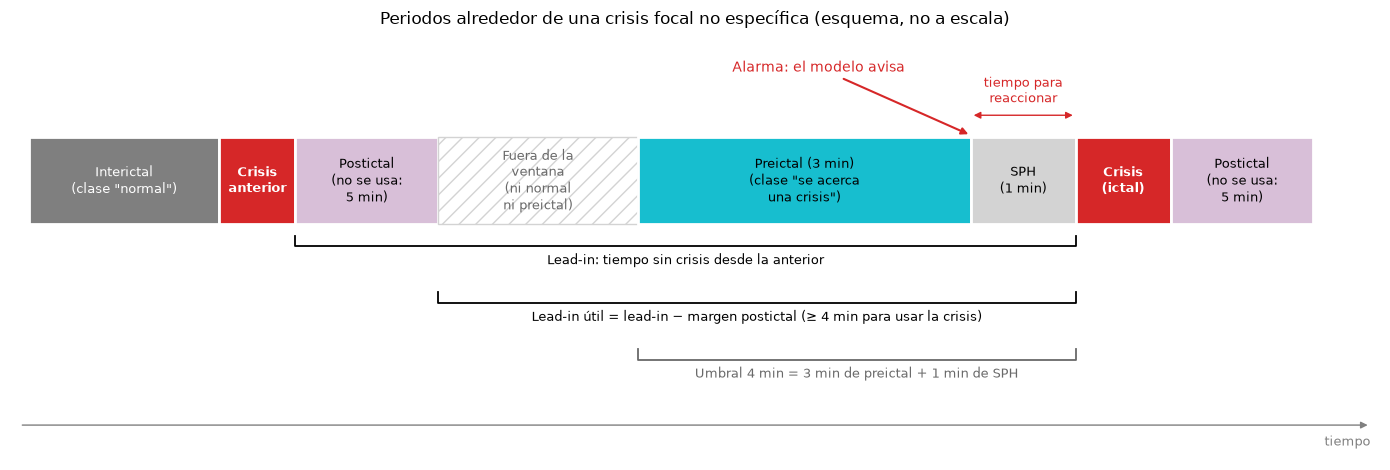

In [6]:
fig, ax = plt.subplots(figsize=(14, 4.8))
dibujar_esquema_periodos(ax, UMBRAL_LEADIN_S, SPH_S, MARGEN_POSTICTAL_S, color_crisis=COLORES_ETIQUETA[TIPO_CRISIS])
ax.set_title(f'Periodos alrededor de una crisis {INFO_TIPO["nombre"]} (esquema, no a escala)')
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'esquema_periodos.png', dpi=150, bbox_inches='tight')
plt.show()

Los mismos términos que aparecen en la figura:

- **Crisis (ictal)**: el periodo en que ocurre la crisis.
- **Interictal**: señal lejos de cualquier crisis. Es la clase **"normal"** del modelo de predicción.
- **Preictal**: el tramo antes de la crisis que el modelo aprenderá a reconocer como **"se acerca una crisis"**. Por defecto, 3 min; en las ausencias, 50 s.
- **Margen** (*SPH, seizure prediction horizon*): hueco entre el final del preictal y el inicio de la crisis. No se usa para entrenar; es el tiempo que tendría el paciente para **reaccionar** tras la alarma. Por defecto, 1 min; en las ausencias, 10 s, porque empiezan de golpe.
- **Alarma**: el momento en que el modelo avisa, al final de la ventana preictal.
- **Postictal**: recuperación tras la crisis. La señal sigue alterada, así que el **margen postictal** no se usa ni como interictal ni como preictal: 5 min por defecto y 0 s en las ausencias, que casi no dejan postictal.
- **Lead-in** (intervalo libre previo): tiempo sin crisis desde el final de la crisis anterior (o desde el inicio del fichero). Descontando el margen postictal de la crisis anterior queda el **lead-in útil**. Solo sirven para predicción las crisis con lead-in útil ≥ el **umbral de su tipo** (4 min por defecto, 60 s en las ausencias), porque necesitan sitio para el preictal más el SPH. En la literatura se habla de *leading seizures* [11, 15].

## 4. Elección de la crisis

Buscamos una crisis que cumpla tres condiciones:

1. Del tipo elegido (`TIPO_CRISIS`).
2. De 🔵 `train`: no miramos 🟢 `eval` para no tomar decisiones viendo el test.
3. **Lead-in útil ≥ el umbral del tipo** (`UMBRAL_LEADIN_S`), para poder dibujar la ventana preictal completa, y además sitio para un **tramo interictal** de al menos 10 s antes del preictal (separado 1 min de él), para poder comparar.

Elegimos automáticamente la crisis con **más lead-in útil** de todas las candidatas: así el ejemplo no depende de una decisión a mano y el notebook funciona igual para cualquier tipo.

In [7]:
df_crisis = pd.read_csv(RUTA_INVENTARIO / 'crisis.csv')
df_crisis['dur_s'] = df_crisis.stop - df_crisis.start
# Lead-in útil: se descuenta el margen postictal de la crisis anterior del fichero (según su tipo)
df_crisis = df_crisis.sort_values(['file', 'start']).reset_index(drop=True)
tipo_anterior = df_crisis.groupby('file').label.shift()
df_crisis['leadin_util_s'] = df_crisis.leadin_s - tipo_anterior.map(margen_postictal_s, na_action='ignore').fillna(0)

MIN_INTERICTAL_S = 10      # duración mínima del tramo interictal de comparación
candidatas = df_crisis[(df_crisis.label == TIPO_CRISIS) & (df_crisis.split == 'train')
                       & (df_crisis.leadin_util_s >= UMBRAL_LEADIN_S + 60 + MIN_INTERICTAL_S)]
candidatas = candidatas.sort_values('leadin_util_s', ascending=False)
assert len(candidatas) > 0, f'No hay crisis {TIPO_CRISIS} en train con lead-in suficiente.'
display(tabla_con_iconos(candidatas[['split', 'patient', 'file', 'label', 'start', 'dur_s', 'leadin_s', 'leadin_util_s']]
                         .set_index('file').round(1), columnas=['split', 'label']))

# La crisis de ejemplo es la candidata con más lead-in útil
crisis_inv = candidatas.iloc[0]
EJEMPLO = crisis_inv.file
config['ejemplo'] = EJEMPLO
with open(RUTA_RESULTADOS / 'configuracion.json', 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=4, ensure_ascii=False)
mostrar_fichero(RUTA_RESULTADOS / 'configuracion.json',
                'parámetros de esta ejecución (tipo de crisis, umbrales de lead-in, SPH y margen postictal) y el fichero de ejemplo elegido')
print(f'Crisis elegida: {con_icono(crisis_inv.label)} de {con_icono(crisis_inv.split)}, {EJEMPLO}, '
      f'inicio {crisis_inv.start:.1f} s, duración {crisis_inv.dur_s:.1f} s, lead-in útil {duracion_legible(crisis_inv.leadin_util_s)}')

,split,patient,label,start,dur_s,leadin_s,leadin_util_s
file,,,,,,,
aaaaacsx_s001_t000,🔵 train,aaaaacsx,🟥 fnsz (♦️),1142.1,30.0,1142.1,1142.1
aaaaalfs_s002_t000,🔵 train,aaaaalfs,🟥 fnsz (♦️),994.1,76.0,994.1,994.1
aaaaardk_s002_t002,🔵 train,aaaaardk,🟥 fnsz (♦️),1520.2,27.0,1216.0,916.0
aaaaabyy_s001_t001,🔵 train,aaaaabyy,🟥 fnsz (♦️),873.0,220.0,873.0,873.0
aaaaamyy_s001_t001,🔵 train,aaaaamyy,🟥 fnsz (♦️),870.7,19.2,870.7,870.7
...,...,...,...,...,...,...,...
aaaaates_s009_t003,🔵 train,aaaaates,🟥 fnsz (♦️),311.9,163.3,311.9,311.9
aaaaaron_s005_t006,🔵 train,aaaaaron,🟥 fnsz (♦️),311.8,257.7,311.8,311.8
aaaaaksh_s004_t000,🔵 train,aaaaaksh,🟥 fnsz (♦️),311.0,59.2,311.0,311.0


💾 **Guardado `configuracion.json`** · 894 B · 12 claves  
*Qué guarda:* parámetros de esta ejecución (tipo de crisis, umbrales de lead-in, SPH y margen postictal) y el fichero de ejemplo elegido. *Abajo:* todas las claves (son pocas).

,valor
clave,
tipo_crisis,fnsz
umbral_leadin_s,240
sph_s,60
ventana_preictal_s,180
margen_postictal_s,300
filtro_hz,"[0.5, 40]"
notch_hz,60
filtro_trazado_hz,"[1, 30]"
bandas_hz,"{""delta"": [0.5, 4], ""theta"": [4, 8], ""alfa"": [8, 13], ""beta"": [13, 30], ""gamma"": [30, 45]}"


Crisis elegida: 🟥 fnsz (♦️) de 🔵 train, aaaaacsx_s001_t000, inicio 1142.1 s, duración 30.0 s, lead-in útil 19 min


👀 **Cómo leer la tabla.** Cada fila es una crisis candidata, ordenadas de más a menos **lead-in útil**; la primera es la elegida. La diferencia entre `leadin_s` y `leadin_util_s` es el **margen postictal** de la crisis anterior, que no cuenta como señal limpia.

## 5. Lectura del EDF con MNE

`leer_edf_tusz` (en `tfm_comun/dataset/edf.py`) hace tres cosas:

1. Lee el EDF con `mne.io.read_raw_edf`. MNE guarda la señal en **voltios**; para verla en µV hay que multiplicar por `1e6`.
2. Limpia los nombres: `'EEG FP1-LE'` → `'FP1'`. El sufijo (`-LE`, `-REF`) indica la **referencia** (ver más abajo).
3. Asigna el **tipo** de cada canal (`eeg`, `ecg`, `eog`...). Qué es cada canal se decide en `tfm_comun/dataset/canales.py`.

El objeto que devuelve se llama `Raw`: la señal continua más su información (`raw.info`).

In [8]:
ruta_edf = buscar_edf(EJEMPLO)
raw = leer_edf_tusz(ruta_edf)
nombres_originales = mne.io.read_raw_edf(ruta_edf, preload=False, verbose='error').ch_names
referencia = pd.Series([referencia_canal(n) for n in nombres_originales]).dropna().mode()[0]

print(f'Fichero:     {ruta_edf.relative_to(RUTA_EDF)}')
print(f'Montaje:     {ruta_edf.parent.name} ({MONTAJES_TUSZ[ruta_edf.parent.name]})')
print(f'Referencia:  -{referencia} = {REFERENCIAS[referencia]}')
print(f'Frecuencia:  {raw.info["sfreq"]:.0f} Hz (muestras por segundo)')
print(f'Duración:    {raw.times[-1]:.0f} s ({raw.times[-1] / 60:.1f} min)')
print(f'Señales:     {len(raw.ch_names)}')
print(f'Matriz:      {raw.get_data().shape} (canales × muestras)')

Fichero:     train\aaaaacsx\s001_2004\02_tcp_le\aaaaacsx_s001_t000.edf
Montaje:     02_tcp_le (orejas unidas (sufijo -LE), TCP de 22 canales)
Referencia:  -LE = orejas unidas (linked ears): media de A1 y A2
Frecuencia:  250 Hz (muestras por segundo)
Duración:    1346 s (22.4 min)
Señales:     33
Matriz:      (33, 336500) (canales × muestras)


### Qué canales trae

No todas las señales del EDF son EEG de cuero cabelludo. Cada canal tiene un **tipo**, con su icono (`tfm_comun/visual/iconos.py`) y su color en las figuras (`tfm_comun/visual/colores.py`), igual que las etiquetas de crisis. MNE define más tipos de los que trae este fichero; la tabla de abajo muestra el catálogo completo que usamos para TUSZ.

Solo los canales 🧠 `eeg` entran en el montaje TCP. El resto (corazón, electrodos especiales, canales sin uso o el marcador de luz `PHOTIC`) se descarta.

In [9]:
canales = pd.DataFrame({'original': nombres_originales, 'nombre': raw.ch_names,
                        'tipo': raw.get_channel_types()})
canales['qué es'] = canales.nombre.map(descripcion_canal)

# Canales de este fichero, agrupados por tipo y descripción
# (nº va entre comillas: como nombre de argumento Python lo convertiría en 'no')
por_tipo = (canales.groupby(['tipo', 'qué es'], sort=False).nombre
            .agg(**{'nº': 'count', 'canales': ', '.join}).reset_index())
por_tipo = por_tipo.sort_values('tipo', key=lambda t: t.map(list(ICONO_TIPO_CANAL).index),
                                kind='stable').set_index('tipo')
print(f'Canales de {EJEMPLO}:')
with pd.option_context('display.max_colwidth', None):
    display(tabla_con_iconos(por_tipo))

# Catálogo completo de tipos de canal
catalogo = pd.DataFrame({'icono': ICONO_TIPO_CANAL, 'qué es': DESCRIPCION_TIPO})
catalogo['en este fichero'] = catalogo.index.map(lambda t: (canales.tipo == t).sum())
catalogo.index.name = 'tipo'
print('Catálogo de tipos de canal (tfm_comun/dataset/canales.py):')
display(catalogo.style.apply(
    lambda fila: [f'border-left: 14px solid {COLORES_TIPO_CANAL[fila.name]}'] + [''] * (len(fila) - 1), axis=1))

Canales de aaaaacsx_s001_t000:


,qué es,nº,canales
tipo,,,
🧠 eeg,electrodo de cuero cabelludo del sistema 10-20,24,"FP1, FP2, F3, F4, C3, C4, A1, A2, P3, P4, O1, O2, F7, F8, T3, T4, T5, T6, FZ, CZ, PZ, OZ, T1, T2"
🫀 ecg,electrocardiograma (actividad del corazón),1,EKG
💡 stim,marcador de estímulo (fotoestimulación con luz),1,PHOTIC
❔ misc,electrodo nasofaríngeo,2,"PG1, PG2"
❔ misc,electrodo esfenoidal,2,"SP2, SP1"
❔ misc,desconocido,2,"RLC, LUC"
❔ misc,entrada del amplificador sin electrodo (sin uso),1,30


Catálogo de tipos de canal (tfm_comun/dataset/canales.py):


,icono,qué es,en este fichero
tipo,,,
eeg,🧠,electrodo de cuero cabelludo del sistema 10-20,24
ecg,🫀,electrocardiograma (actividad del corazón),1
eog,👁️,electrooculograma (movimientos de los ojos),0
emg,💪,electromiograma (actividad muscular),0
stim,💡,marcador de estímulo (fotoestimulación con luz),1
resp,🫁,respiración,0
misc,❔,"otros: electrodos especiales, canales sin uso o calculados por el equipo",7


### Referencias: `-LE`, `-REF` y la variante sin orejas

Un electrodo no mide un voltaje "absoluto": mide la **diferencia** entre su punto y un punto de **referencia**. Esa referencia se ve en **el final del nombre de cada canal dentro del EDF** (no en el nombre del fichero). En TUSZ hay dos referencias y una variante [5, 6]:

| Montaje (carpeta) | Referencia | Cómo se llaman los canales en el EDF |
|---|---|---|
| `02_tcp_le` | **Orejas unidas** (*linked ears*): la media de los electrodos de las orejas, A1 y A2 | `EEG FP1-LE`, `EEG T3-LE`… |
| `01_tcp_ar` | **Media de todos los electrodos** (*averaged reference*, AR) | `EEG FP1-REF`, `EEG T3-REF`… |
| `03_tcp_ar_a` | La misma media, pero el fichero **no trae A1 ni A2**: el montaje TCP queda en **20 canales** | `EEG FP1-REF`, `EEG T3-REF`… |

**Ojo con la confusión**: la carpeta se llama `_ar` (de *averaged reference*), pero dentro del EDF los canales **no** acaban en `-AR`, sino en **`-REF`**. Así que hay dos pistas para saber la referencia de un fichero: el nombre de su carpeta y el sufijo de sus canales.

En el código, `limpiar_nombre_canal` (en `tfm_comun/dataset/canales.py`) quita ese sufijo (`'EEG FP1-REF'` → `'FP1'`) y `referencia_canal` lo usa para saber qué referencia tiene el fichero.

La documentación describe un cuarto montaje, `04_tcp_le_a`, que no aparece en la v2.0.6.

In [10]:
df_ficheros = pd.read_csv(RUTA_INVENTARIO / 'edfs.csv')
montajes = (pd.crosstab(df_ficheros.montage, df_ficheros.split, margins=True, margins_name='todas')
            .reindex(columns=['train', 'dev', 'eval', 'todas']))
montajes = montajes.reindex(MONTAJES_TUSZ).fillna(0).astype(int).drop(index='todas', errors='ignore')
montajes['qué es'] = montajes.index.map(MONTAJES_TUSZ)
print('Nº de EDF por montaje y partición:')
display(tabla_con_iconos(montajes))

Nº de EDF por montaje y partición:


split,🔵 train,🟡 dev,🟢 eval,⚪ todas,qué es
montage,,,,,
01_tcp_ar,3412,1868,821,6101,"referencia promedio (sufijo -REF), TCP de 22 c..."
02_tcp_le,522,51,0,573,"orejas unidas (sufijo -LE), TCP de 22 canales"
03_tcp_ar_a,1123,284,59,1466,"referencia promedio sin A1/A2, TCP de 20 canales"
04_tcp_le_a,0,0,0,0,"orejas unidas sin A1/A2 (documentado, no apare..."


### El sistema internacional 10-20

Los electrodos se colocan siguiendo el **sistema 10-20** [3, 4], el estándar mundial para que un `C3` esté en el mismo sitio en cualquier hospital:

- Se mide la cabeza de **delante a atrás** (de la nariz, *nasion*, a la protuberancia de la nuca, *inion*) y de **oreja a oreja**.
- Los electrodos se colocan a intervalos del **10 % y el 20 %** de esas distancias. De ahí el nombre.
- La **letra** indica la región: `Fp` frontopolar, `F` frontal, `C` central, `T` temporal, `P` parietal, `O` occipital, `A` auricular (orejas).
- El **número**: **impar = izquierda**, **par = derecha**; `z` (de *zero*) = línea media.

TUSZ usa la nomenclatura **antigua**: `T3`, `T4`, `T5`, `T6` se llaman hoy `T7`, `T8`, `P7`, `P8` [4].

Cada región tiene un **color** y un **icono** (un cuadrado del mismo color), que usaremos en todas las figuras de electrodos.

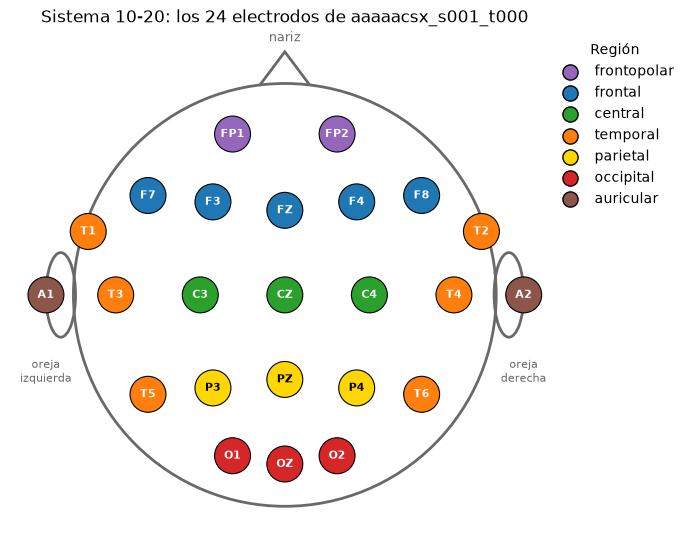

,electrodos,en el montaje TCP
región,,
🟪 frontopolar,"FP1, FP2","FP1, FP2"
🟦 frontal,"F3, F4, F7, F8, FZ","F3, F4, F7, F8"
🟩 central,"C3, C4, CZ","C3, C4, CZ"
🟧 temporal,"T3, T4, T5, T6, T1, T2","T3, T4, T5, T6"
🟨 parietal,"P3, P4, PZ","P3, P4"
🟥 occipital,"O1, O2, OZ","O1, O2"
🟫 auricular,"A1, A2","A1, A2"


In [11]:
electrodos = [c for c in raw.ch_names if region_electrodo(c)]
electrodos_tcp = sorted({e for par in PARES_TCP for e in par} & set(electrodos))   # sin A1/A2 en 03_tcp_ar_a

fig, ax = plt.subplots(figsize=(7, 7))
dibujar_contorno(ax)
dibujar_electrodos(ax, electrodos)
for region in REGIONES:
    ax.scatter([], [], s=120, color=COLORES_REGION[region], edgecolor='black', label=region)
ax.legend(loc='upper left', bbox_to_anchor=(0.97, 1), title='Región', frameon=False)
ax.text(0, 1.2, 'nariz', ha='center', fontsize=9, color='dimgray')
ax.text(-1.13, -0.3, 'oreja\nizquierda', ha='center', va='top', fontsize=8, color='dimgray')
ax.text(1.13, -0.3, 'oreja\nderecha', ha='center', va='top', fontsize=8, color='dimgray')
ax.set_title(f'Sistema 10-20: los {len(electrodos)} electrodos de {EJEMPLO}')
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'sistema_10_20.png', dpi=150, bbox_inches='tight')
plt.show()

tabla_regiones = pd.DataFrame({
    'electrodos': [', '.join(e for e in electrodos if region_electrodo(e) == r) for r in REGIONES],
    'en el montaje TCP': [', '.join(e for e in electrodos_tcp if region_electrodo(e) == r) for r in REGIONES]},
    index=REGIONES)
tabla_regiones.index.name = 'región'
display(tabla_con_iconos(tabla_regiones))

## 6. Anotaciones: dónde están las crisis

Leemos los dos ficheros de anotaciones (formato explicado en la sección 5 del notebook 01):

- `.csv_bi` (**bi**nario): inicio y fin de cada crisis, para todo el fichero (canal `TERM`). Solo distingue ⬛ `seiz` (crisis) de ⬜ `bckg` (fondo).
- `.csv`: lo mismo **canal a canal** (canales TCP) y **con el tipo de crisis** (🟩 `absz` (🔹), 🟨 `tnsz` (🔷)...).

**¿Por qué el `.csv_bi` dice `seiz` y no el tipo?** Porque es la versión simplificada para detección binaria: solo responde "¿hay crisis o no?". Sí, en ese tiempo hay anotada una crisis; su **tipo no se pierde**, está en el `.csv`. Los dos ficheros marcan exactamente los mismos tiempos.

.csv_bi (binarias):


,channel,start_time,stop_time,label,confidence,inicio_min,fin_min
0,TERM,1142.072,1172.0666,⬛ seiz,1.0,19.03,19.53


.csv (por canal): 5 filas. Canales con crisis en cada evento:


nº canales TCP
start_time stop_time inicio_min fin_min label                      
1142.072   1172.0408 19.03      19.53   🟥 fnsz (♦️)               1
           1172.0574 19.03      19.53   🟥 fnsz (♦️)               1
1164.9301  1172.0333 19.42      19.53   🟥 fnsz (♦️)               1
1164.9412  1172.0666 19.42      19.53   🟥 fnsz (♦️)               1
1164.9523  1172.0555 19.42      19.53   🟥 fnsz (♦️)               1

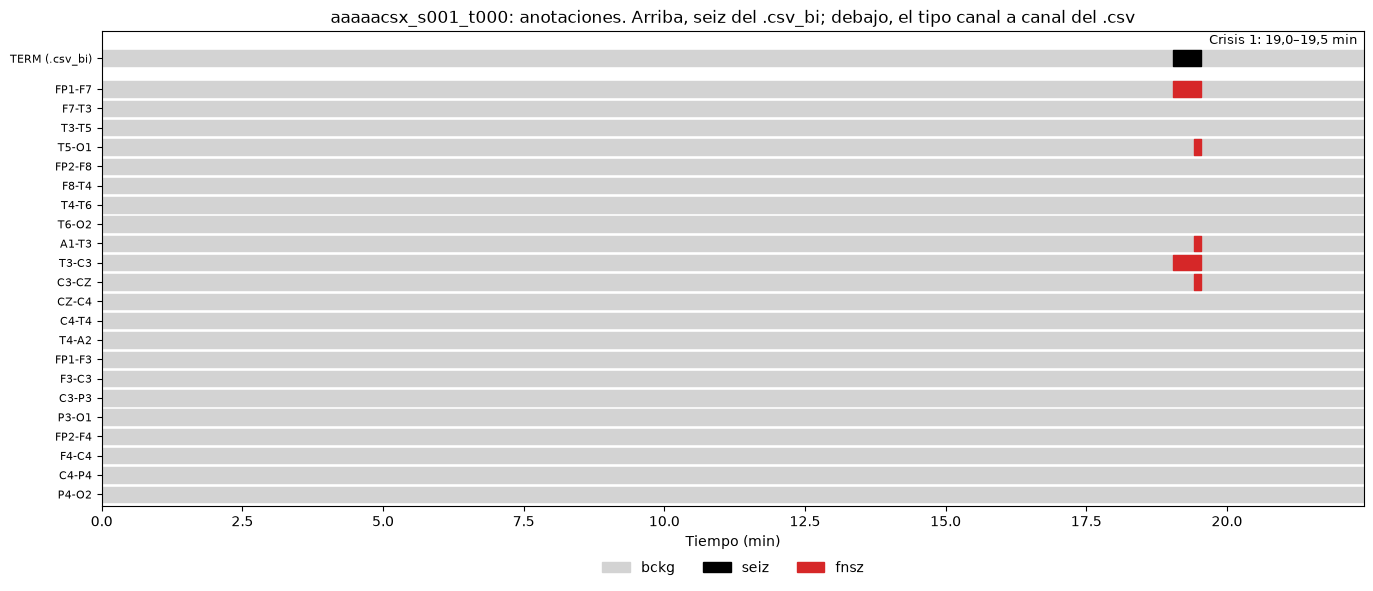

In [12]:
anot_bi = leer_anotaciones(ruta_edf, binarias=True)
anot_canal = leer_anotaciones(ruta_edf)

# Columnas en minutos, para cruzarlas con la línea de tiempo de abajo (que va en minutos)
for anot in (anot_bi, anot_canal):
    anot['inicio_min'] = (anot.start_time / 60).round(2)
    anot['fin_min'] = (anot.stop_time / 60).round(2)

print('.csv_bi (binarias):')
display(tabla_con_iconos(anot_bi, columnas=['label']))
print(f'.csv (por canal): {len(anot_canal)} filas. Canales con crisis en cada evento:')
display(tabla_con_iconos(anot_canal[anot_canal.label != 'bckg']
                         .groupby(['start_time', 'stop_time', 'inicio_min', 'fin_min', 'label']).channel.nunique()
                         .rename('nº canales TCP').to_frame()))

# Línea de tiempo de las anotaciones: arriba el .csv_bi, debajo el .csv canal a canal
dur_min = raw.times[-1] / 60
crisis_tipos = list(dict.fromkeys(anot_canal.label[anot_canal.label != 'bckg']))   # tipos presentes
# Canales TCP que se pueden construir con este EDF (20 en 03_tcp_ar_a, 22 en el resto), en el orden de TUSZ.
# Algunos .csv solo listan los canales con crisis; los demás son fondo (bckg) todo el fichero
canales_csv = [f'{a}-{c}' for a, c in PARES_TCP if a in raw.ch_names and c in raw.ch_names]
fig, ax = plt.subplots(figsize=(14, 6))
for fila, (fuente, anot) in enumerate([('TERM (.csv_bi)', anot_bi)] +
                                      [(c, anot_canal[anot_canal.channel == c]) for c in canales_csv]):
    y = -fila - (0.6 if fila > 0 else 0)                   # hueco entre el .csv_bi y el .csv
    ax.broken_barh([(0, dur_min)], (y - 0.4, 0.8), color=COLORES_ETIQUETA['bckg'])   # fondo: lo no anotado
    for _, a in anot.iterrows():
        ax.broken_barh([(a.start_time / 60, (a.stop_time - a.start_time) / 60)], (y - 0.4, 0.8),
                       color=COLORES_ETIQUETA[a.label])
ax.set_yticks([0] + [-f - 0.6 for f in range(1, len(canales_csv) + 1)])
ax.set_yticklabels(['TERM (.csv_bi)'] + canales_csv, fontsize=8)
leyenda = [Patch(color=COLORES_ETIQUETA[e], label=e) for e in dict.fromkeys(['bckg', 'seiz', *crisis_tipos])]
for i, a in enumerate(anot_bi[anot_bi.label == 'seiz'].itertuples()):
    ax.annotate(f'Crisis {i + 1}: {a.start_time / 60:.1f}–{a.stop_time / 60:.1f} min'.replace('.', ','),
                xy=(a.stop_time / 60, 0.45), xytext=(6, 4), textcoords='offset points', fontsize=9)
ax.set_xlim(0, dur_min)
ax.set_ylim(-len(canales_csv) - 1.2, 1.4)
ax.set_xlabel('Tiempo (min)')
ax.set_title(f'{EJEMPLO}: anotaciones. Arriba, seiz del .csv_bi; debajo, el tipo canal a canal del .csv')
ax.legend(handles=leyenda, loc='upper center', bbox_to_anchor=(0.5, -0.09), ncol=3, frameon=False)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'anotaciones_linea_tiempo.png', dpi=150, bbox_inches='tight')
plt.show()

Si la crisis aparece en **todos** los canales TCP a la vez, es **generalizada**: afecta a todo el cerebro desde el inicio (como la ausencia o la tónica). En una crisis **focal** (🟥 `fnsz` (♦️)) solo aparecería en unos pocos canales.

`crisis_del_fichero` (en `tfm_comun/dataset/anotaciones.py`) junta las dos fuentes: una fila por crisis, con los tiempos del `.csv_bi` y el tipo del `.csv`. Después la pasamos al `Raw` como **anotaciones de MNE**, para que la señal "sepa" dónde están las crisis.

In [13]:
crisis = crisis_del_fichero(ruta_edf)
crisis['leadin_s'] = crisis.inicio_s - crisis.fin_s.shift(fill_value=0)
# Lead-in útil: se descuenta el margen postictal de la crisis anterior (según su tipo)
crisis['leadin_util_s'] = crisis.inicio_s - (crisis.fin_s + crisis.tipo.map(margen_postictal_s)).shift(fill_value=0)
raw.set_annotations(a_anotaciones_mne(crisis))

# Para mostrar, también en minutos (como en la línea de tiempo); el CSV se guarda en segundos
display(tabla_con_iconos(crisis.assign(inicio_min=crisis.inicio_s / 60, fin_min=crisis.fin_s / 60,
                                       leadin_min=crisis.leadin_s / 60).round(2), columnas=['tipo']))
print(raw.annotations)

# Crisis de ejemplo y sus periodos (en segundos desde el inicio del fichero)
CRISIS = crisis.loc[(crisis.inicio_s - crisis_inv.start).abs().idxmin()]
t_crisis, t_fin_crisis = CRISIS.inicio_s, CRISIS.fin_s
t_margen = t_crisis - SPH_S
t_preictal = t_margen - VENTANA_PREICTAL_S
# Fin del margen postictal de la crisis anterior (o inicio del fichero): los tramos interictales no pueden empezar antes
anteriores = crisis[crisis.fin_s <= t_crisis]
t_libre = (anteriores.fin_s + anteriores.tipo.map(margen_postictal_s)).max() if len(anteriores) else 0

# Canales TCP donde está anotada la crisis de ejemplo (en una focal, solo unos pocos)
canales_crisis = anot_canal[(anot_canal.label != 'bckg') & (anot_canal.start_time < t_fin_crisis)
                            & (anot_canal.stop_time > t_crisis)].channel.unique().tolist()
n_canales_crisis = len(canales_crisis)
print(f'La crisis de ejemplo aparece en {n_canales_crisis} de {len(canales_csv)} canales TCP -> '
      f'{"generalizada" if n_canales_crisis == len(canales_csv) else "focal o parcial: " + ", ".join(canales_crisis)}')
print(f'\nCrisis de ejemplo {con_icono(CRISIS.tipo)}: {t_crisis:.1f}–{t_fin_crisis:.1f} s '
      f'({t_crisis / 60:.2f}–{t_fin_crisis / 60:.2f} min) | '
      f'preictal {t_preictal / 60:.2f}–{t_margen / 60:.2f} min | margen {t_margen / 60:.2f}–{t_crisis / 60:.2f} min')

,inicio_s,fin_s,tipo,duracion_s,leadin_s,leadin_util_s,inicio_min,fin_min,leadin_min
0,1142.07,1172.07,🟥 fnsz (♦️),29.99,1142.07,1142.07,19.03,19.53,19.03


<Annotations | 1 segment: fnsz (1)>
La crisis de ejemplo aparece en 5 de 22 canales TCP -> focal o parcial: FP1-F7, T5-O1, A1-T3, T3-C3, C3-CZ

Crisis de ejemplo 🟥 fnsz (♦️): 1142.1–1172.1 s (19.03–19.53 min) | preictal 15.03–18.03 min | margen 18.03–19.03 min


## 7. Montaje TCP de 22 canales

El EDF es **referencial**: cada electrodo se mide contra la misma referencia (las orejas con `-LE`, la media de todos con `-REF`). El montaje **TCP** es **bipolar**: cada canal es la resta de dos electrodos vecinos, y la referencia se cancela:

```
FP1-F7 = (FP1 - ref) - (F7 - ref) = FP1 - F7
```

Ventajas:

- **Da igual la referencia original**: un fichero `01_tcp_ar` y uno `02_tcp_le` acaban con los mismos 22 canales. Resuelve la mezcla de montajes que vimos en el EDA.
- Es el montaje en el que **TUSZ anota las crisis** (`.csv` por canal), así que las etiquetas encajan canal a canal.

Los 22 canales forman **5 cadenas** de electrodos vecinos, de delante a atrás (y de oreja a oreja en la central). En la figura, cada flecha es un canal: va del electrodo que suma (ánodo) al que resta (cátodo).

Canales TCP: 22 (esperados 22)
Las anotaciones se conservan: 1 crisis
Comprobación FP1-F7 = FP1 - F7: error máximo 0.0e+00 V


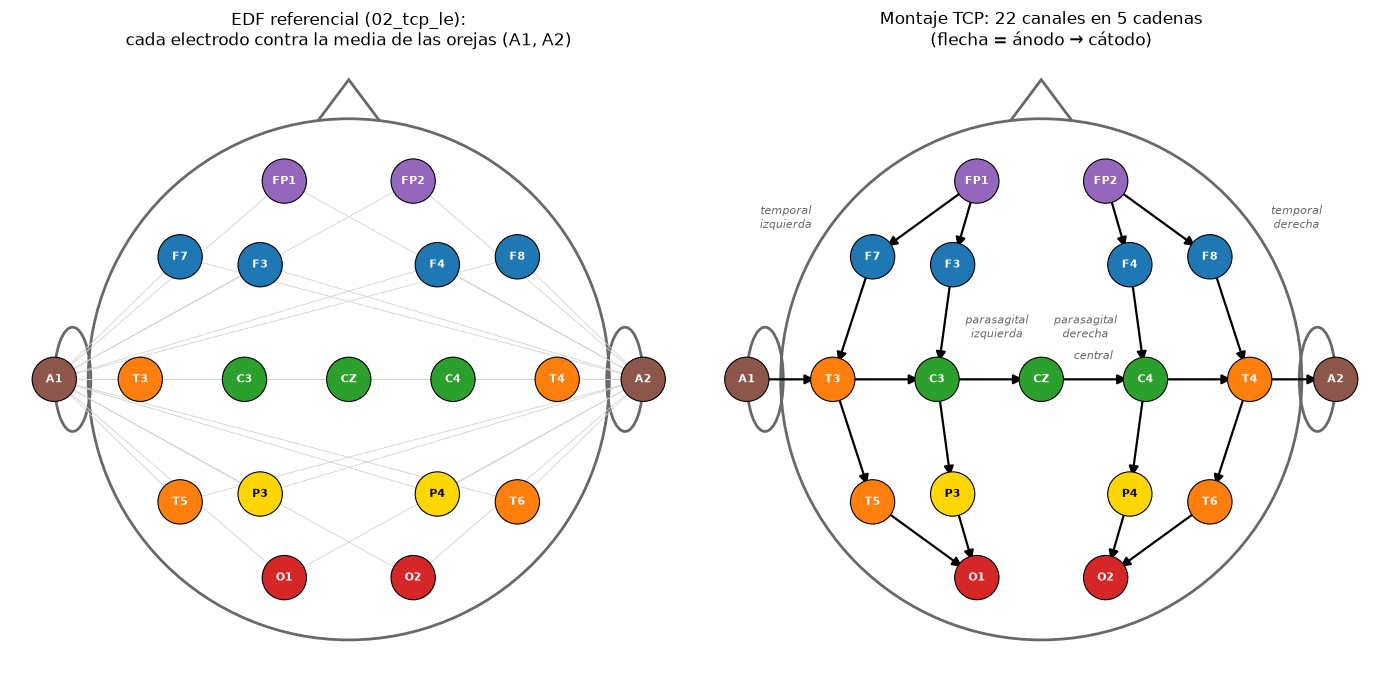

,canales,nº
cadena,,
temporal izquierda,"FP1-F7, F7-T3, T3-T5, T5-O1",4
temporal derecha,"FP2-F8, F8-T4, T4-T6, T6-O2",4
central,"A1-T3, T3-C3, C3-CZ, CZ-C4, C4-T4, T4-A2",6
parasagital izquierda,"FP1-F3, F3-C3, C3-P3, P3-O1",4
parasagital derecha,"FP2-F4, F4-C4, C4-P4, P4-O2",4


In [14]:
tcp = montaje_tcp(raw)

print(f'Canales TCP: {len(tcp.ch_names)} (esperados {len(PARES_TCP)})')
print(f'Las anotaciones se conservan: {len(tcp.annotations)} crisis')

# Comprobación: FP1-F7 tiene que ser exactamente FP1 - F7
diferencia = tcp.get_data(picks='FP1-F7') - (raw.get_data(picks='FP1') - raw.get_data(picks='F7'))
print(f'Comprobación FP1-F7 = FP1 - F7: error máximo {np.abs(diferencia).max():.1e} V')

fig, (ax_ref, ax_tcp) = plt.subplots(1, 2, figsize=(14, 7))
# Izquierda: montaje referencial. Con -LE cada electrodo se mide contra la media de las orejas;
# con -REF (AR), contra la media de todos los electrodos (la dibujamos como una estrella en el centro)
dibujar_contorno(ax_ref)
destinos = [POSICIONES_1020['A1'], POSICIONES_1020['A2']] if referencia == 'LE' else [(0, -0.2)]
for e in electrodos_tcp:
    if region_electrodo(e) != 'auricular' or referencia != 'LE':
        for destino in destinos:
            ax_ref.plot(*zip(POSICIONES_1020[e], destino), color='lightgray', linewidth=0.6, zorder=1)
if referencia != 'LE':
    ax_ref.plot(0, -0.2, marker='*', markersize=18, color='dimgray', zorder=4)
    ax_ref.text(0, -0.3, 'media de todos', ha='center', va='top', fontsize=8, color='dimgray')
dibujar_electrodos(ax_ref, electrodos_tcp)
texto_ref = 'la media de las orejas (A1, A2)' if referencia == 'LE' else 'la media de todos los electrodos'
ax_ref.set_title(f'EDF referencial ({ruta_edf.parent.name}):\ncada electrodo contra {texto_ref}')

# Derecha: montaje TCP (cada flecha es un canal = ánodo - cátodo)
dibujar_contorno(ax_tcp)
dibujar_pares(ax_tcp, [p for p in PARES_TCP if f'{p[0]}-{p[1]}' in tcp.ch_names])
dibujar_electrodos(ax_tcp, electrodos_tcp)
for texto, (x, y) in {'temporal\nizquierda': (-0.98, 0.62), 'temporal\nderecha': (0.98, 0.62),
                      'parasagital\nizquierda': (-0.17, 0.2), 'parasagital\nderecha': (0.17, 0.2),
                      'central': (0.2, 0.09)}.items():
    ax_tcp.text(x, y, texto, ha='center', va='center', fontsize=8, style='italic', color='dimgray')
ax_tcp.set_title(f'Montaje TCP: {len(tcp.ch_names)} canales en 5 cadenas\n(flecha = ánodo → cátodo)')
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'montaje_tcp.png', dpi=150, bbox_inches='tight')
plt.show()

cadenas = pd.DataFrame({'canales': [', '.join(f'{a}-{c}' for a, c in pares) for pares in CADENAS_TCP.values()],
                        'nº': [len(p) for p in CADENAS_TCP.values()]}, index=list(CADENAS_TCP))
cadenas.index.name = 'cadena'
display(cadenas)

## 8. Filtrado para visualizar

- **Notch a 60 Hz**: quita el zumbido de la red eléctrica.
- **Paso banda 0,5–40 Hz**: quita la deriva lenta (sudor, movimiento de electrodos) y el ruido muscular rápido. La firma de la crisis queda dentro.
- Para las **bandas** (sección 13) usamos otra copia **sin el corte de 40 Hz**, porque gamma llega hasta 45 Hz.

Trabajamos sobre **copias** (`.copy()`): en MNE casi todo modifica el objeto original.

In [15]:
tcp_filtrado = tcp.copy().notch_filter(NOTCH_HZ, verbose='error').filter(*FILTRO_HZ, verbose='error')
tcp_bandas = tcp.copy().notch_filter(NOTCH_HZ, verbose='error').filter(FILTRO_HZ[0], None, verbose='error')

FS = tcp_filtrado.info['sfreq']
senal_uv = tcp_filtrado.get_data() * 1e6           # (22 canales, muestras) en µV, 0,5–40 Hz
senal_bandas_uv = tcp_bandas.get_data() * 1e6      # igual, pero sin cortar por arriba (para gamma)
tiempos = tcp_filtrado.times
print(f'Señal filtrada: {senal_uv.shape}, {FS:.0f} Hz')

Señal filtrada: (22, 336500), 250 Hz


### Qué hace el filtro: el espectro antes y después

El **espectro** o **PSD** (*power spectral density*) dice **cuánta potencia hay en cada frecuencia**. Se calcula con el **método de Welch**, que se explica en la sección 11. Lo dibujamos para los electrodos del fichero, antes y después de filtrar:

- **Color** = región de la cabeza (el mismo que en la cabeza de la sección 5).
- **Tipo de línea** = lado: continua **izquierda** (número impar: `FP1`, `C3`…), discontinua **derecha** (número par: `FP2`, `C4`…), punteada **línea media** (`FZ`, `CZ`…). Así se distinguen dos electrodos de la misma región.
- **Leyenda** con el nombre de cada electrodo.
- `ELECTRODOS_PSD`: lista de electrodos a dibujar (por ejemplo `['FP1', 'FP2']`) para verlos por separado; `None` dibuja todos.

Qué buscar:

- **Antes**: un pico muy estrecho a **60 Hz** (la red eléctrica) y mucha potencia en las frecuencias muy bajas (derivas).
- **Después**: el pico de 60 Hz desaparece y la potencia cae fuera de 0,5–40 Hz (zonas sombreadas).
- La potencia baja al subir la frecuencia (forma "1/f"): es lo normal en un EEG.
- Si una línea va **muy por encima** del resto, ese electrodo es **ruidoso** (mal contacto). Lo detectamos automáticamente debajo de la figura.
- Con referencia de orejas (`-LE`), las líneas marrones (`A1`, `A2`) van por debajo: la oreja se mide casi contra sí misma.

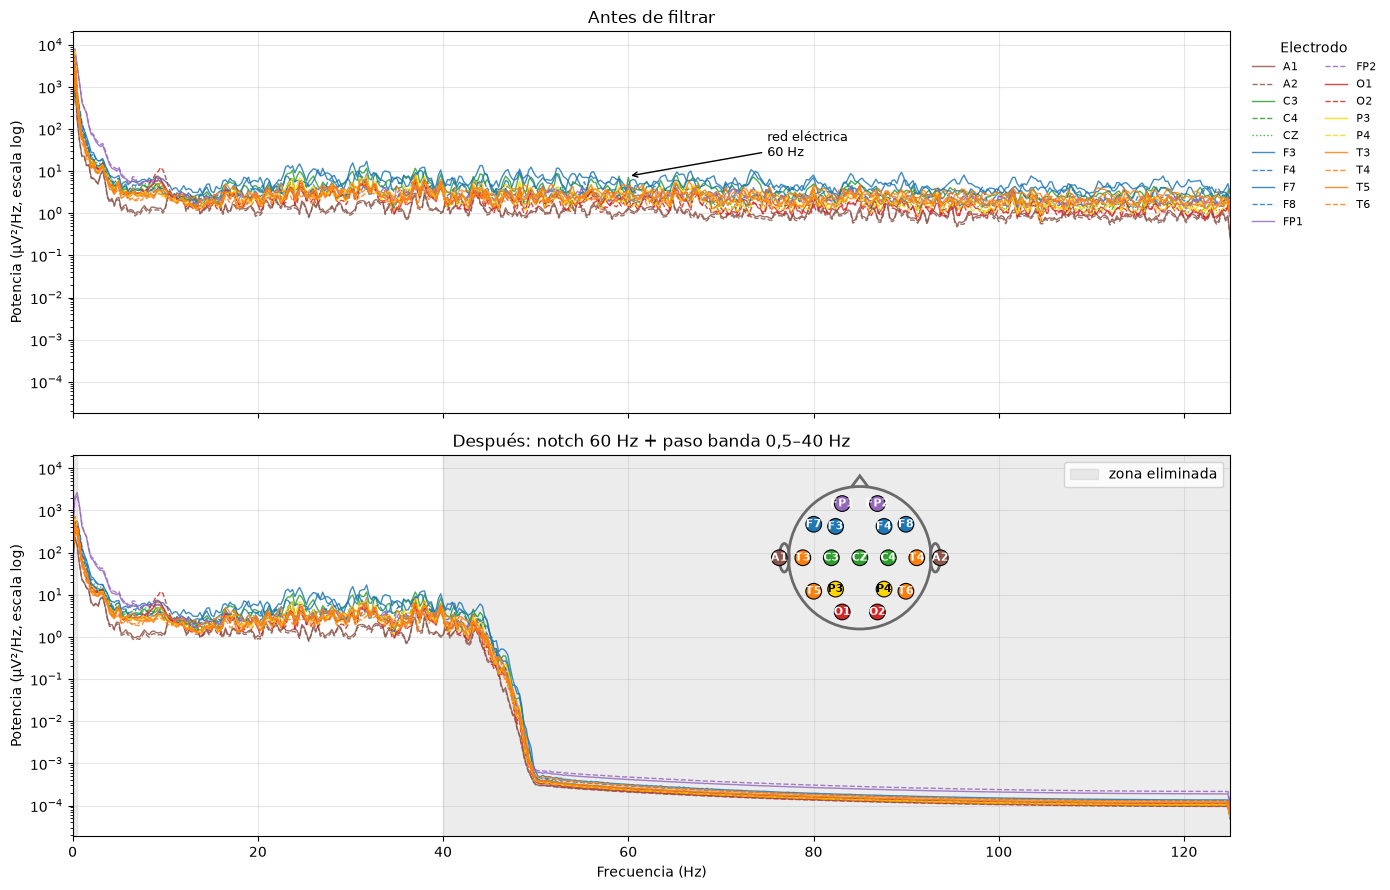

🔴 OZ: 29 veces la potencia típica -> electrodo ruidoso (no entra en el montaje TCP)
Potencia a 60 Hz: 9.757,6 veces menor tras el filtro


In [16]:
# Electrodos a dibujar: lista (p. ej. ['FP1', 'FP2']) o None para todos
#ELECTRODOS_PSD = ['FP1', 'O1']
ELECTRODOS_PSD = electrodos_tcp

eeg = raw.copy().pick(electrodos)
eeg_filtrado = eeg.copy().notch_filter(NOTCH_HZ, verbose='error').filter(*FILTRO_HZ, verbose='error')

# Espectro de Welch con ventanas de 4 s (resolución de 0,25 Hz). MNE lo da en V²/Hz -> ×1e12 = µV²/Hz
psd_antes = eeg.compute_psd(method='welch', fmax=FS / 2, n_fft=int(4 * FS), picks=ELECTRODOS_PSD,
                            verbose='error')
psd_despues = eeg_filtrado.compute_psd(method='welch', fmax=FS / 2, n_fft=int(4 * FS), picks=ELECTRODOS_PSD,
                                       verbose='error')

# Un panel debajo del otro, con los mismos ejes, para comparar antes y después
fig, ejes = plt.subplots(2, 1, figsize=(14, 9), sharex=True, sharey=True)
for ax, psd, titulo in [(ejes[0], psd_antes, 'Antes de filtrar'),
                        (ejes[1], psd_despues, f'Después: notch {NOTCH_HZ} Hz + paso banda '
                                               f'{numero_legible(FILTRO_HZ[0])}–{FILTRO_HZ[1]} Hz')]:
    datos = psd.get_data() * 1e12
    for nombre, fila in zip(psd.ch_names, datos):
        # Color = región; tipo de línea = lado de la cabeza (FP1 continua, FP2 discontinua)
        ax.semilogy(psd.freqs, fila, color=COLORES_REGION[region_electrodo(nombre)],
                    linestyle=ESTILOS_LADO[lado_electrodo(nombre)], linewidth=1, alpha=0.85, label=nombre)
    ax.set_xlim(0, FS / 2)
    ax.set_ylabel('Potencia (µV²/Hz, escala log)')
    ax.set_title(titulo)
    ax.grid(True, alpha=0.3)
ejes[1].set_xlabel('Frecuencia (Hz)')
pico_60 = psd_antes.get_data(fmin=59, fmax=61).max() * 1e12
ejes[0].annotate('red eléctrica\n60 Hz', xy=(60, pico_60), xytext=(75, pico_60 * 3), fontsize=9,
                 arrowprops=dict(arrowstyle='->'))
ejes[1].axvspan(0, FILTRO_HZ[0], color='gray', alpha=0.15)
ejes[1].axvspan(FILTRO_HZ[1], FS / 2, color='gray', alpha=0.15, label='zona eliminada')
# Leyenda con el nombre de cada electrodo, fuera del gráfico (a la derecha) para no tapar las líneas
ejes[0].legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=8, title='Electrodo',
               ncol=1 if len(psd_antes.ch_names) <= 12 else 2, frameon=False)
ejes[1].legend(handles=ejes[1].get_legend_handles_labels()[0][-1:], loc='upper right')
# Escala log en potencias de 10: el rango abarca muchos órdenes de magnitud

# Cabeza pequeña con los electrodos dibujados, en sus colores
ax_cabeza = ejes[1].inset_axes([0.6, 0.5, 0.16, 0.48])   # en la zona eliminada, que está vacía
dibujar_contorno(ax_cabeza)
dibujar_electrodos(ax_cabeza, psd_antes.ch_names, tamano=0.11, etiquetas=True)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'espectro_antes_despues_filtro.png', dpi=150, bbox_inches='tight')
plt.show()

# Electrodos ruidosos: potencia media más de 10 veces la mediana. Siempre con TODOS los electrodos,
# aunque arriba se dibujen solo unos pocos (con dos electrodos la mediana no significaría nada)
psd_todos = eeg.compute_psd(method='welch', fmax=40, n_fft=int(4 * FS), verbose='error')
potencia_media = pd.Series(psd_todos.get_data().mean(axis=1), index=psd_todos.ch_names)
ruidosos = potencia_media[potencia_media > 10 * potencia_media.median()]
for e, p in ruidosos.items():
    print(f'🔴 {e}: {p / potencia_media.median():.0f} veces la potencia típica -> electrodo ruidoso '
          f'({"entra" if e in electrodos_tcp else "no entra"} en el montaje TCP)')
if ruidosos.empty:
    print('Ningún electrodo destaca por exceso de potencia.')


def potencia_cerca(psd, f0, ancho=1):
    return psd.get_data(fmin=f0 - ancho, fmax=f0 + ancho).mean()

print(f'Potencia a 60 Hz: {numero_legible(potencia_cerca(psd_antes, 60) / potencia_cerca(psd_despues, 60))} veces '
      f'menor tras el filtro')

### Las ondas del EEG, banda a banda

El EEG es una **suma de ondas de distintas frecuencias**. Si filtramos la señal para quedarnos con cada banda por separado, vemos de qué está hecha. Comparamos 4 s **interictales** con 4 s **en mitad de la crisis**, en el mismo canal y con la misma escala en cada fila.

Lo que hay que ver: **qué bandas crecen** en la crisis respecto a la señal normal. La escala de cada fila está a la derecha.

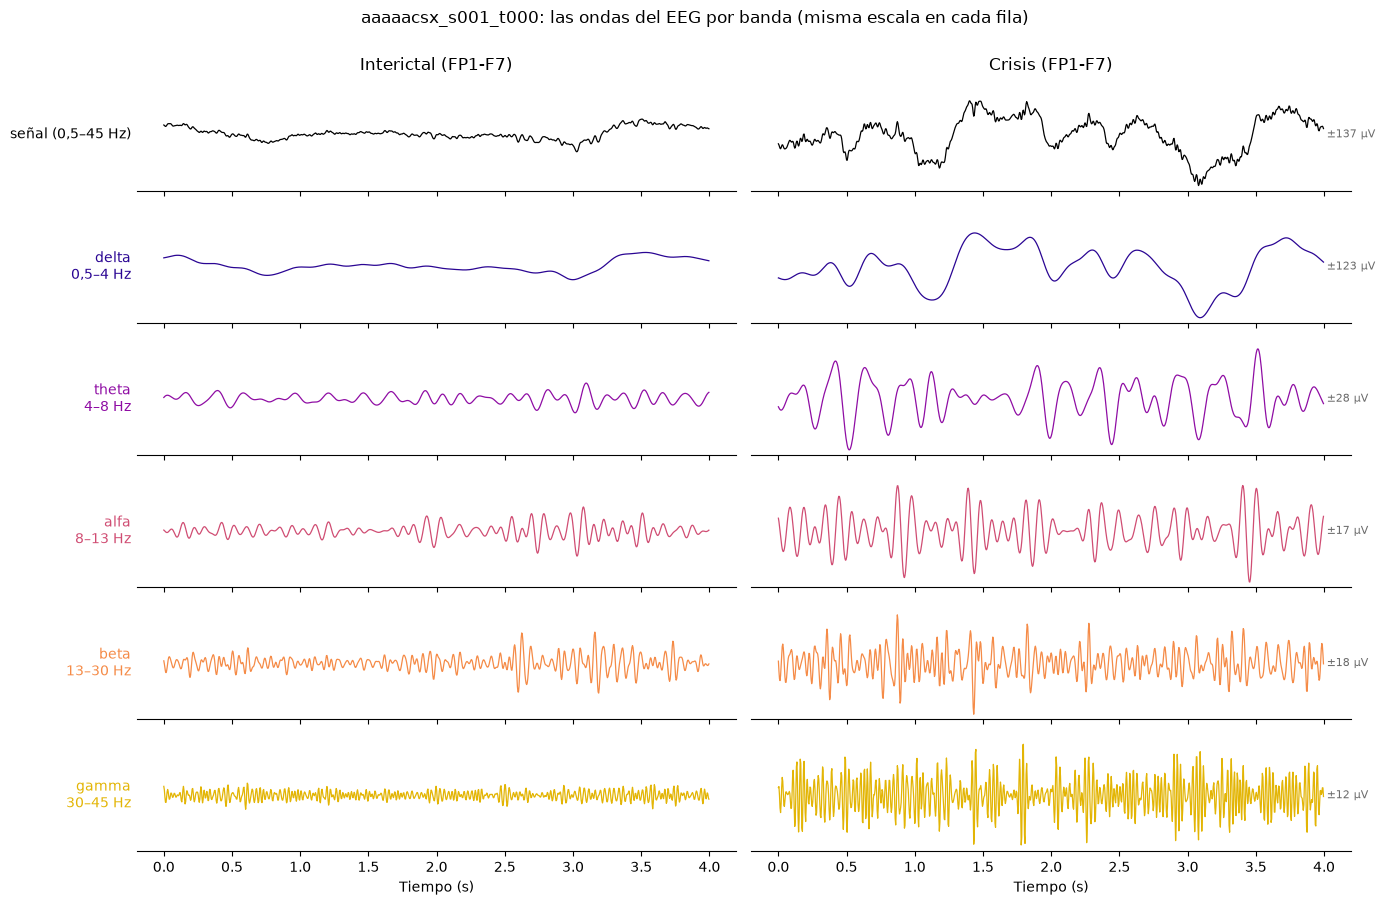

In [17]:
CANAL_ONDAS = canales_crisis[0] if 'F3-C3' not in canales_crisis else 'F3-C3'   # un canal donde está la crisis
i_canal = tcp.ch_names.index(CANAL_ONDAS)
centro_crisis = (t_crisis + t_fin_crisis) / 2
tramos_ondas = {'Interictal': max(t_libre, t_preictal - 60 - 4),   # inicio de cada tramo de 4 s
                'Crisis': centro_crisis - 2}

# Cada fila: la señal completa (0,5–45 Hz) y luego cada banda filtrada por separado
filas = {'señal (0,5–45 Hz)': (0.5, 45), **BANDAS_HZ}
ondas = {}
for nombre_tramo, t0 in tramos_ondas.items():
    tramo_ondas = (tiempos >= t0) & (tiempos < t0 + 4)
    x = senal_bandas_uv[i_canal]
    ondas[nombre_tramo] = {f: mne.filter.filter_data(x, FS, lo, hi, verbose='error')[tramo_ondas]
                           for f, (lo, hi) in filas.items()}

fig, ejes = plt.subplots(len(filas), 2, figsize=(14, 9), sharex=True)
for fila, nombre_fila in enumerate(filas):
    escala = max(np.abs(ondas[t][nombre_fila]).max() for t in ondas) * 1.1   # misma escala en la fila
    color = COLORES_BANDA.get(nombre_fila, 'black')
    for col, nombre_tramo in enumerate(ondas):
        ax = ejes[fila, col]
        y = ondas[nombre_tramo][nombre_fila]
        ax.plot(np.arange(len(y)) / FS, y, color=color, linewidth=0.9)
        ax.set_ylim(-escala, escala)
        ax.set_yticks([])
        ax.spines[['top', 'right', 'left']].set_visible(False)
        if fila == 0:
            ax.set_title(f'{nombre_tramo} ({CANAL_ONDAS})', fontsize=12)
    lo, hi = filas[nombre_fila]
    etiqueta = nombre_fila if nombre_fila.startswith('señal') else f'{nombre_fila}\n{numero_legible(lo)}–{hi} Hz'
    ejes[fila, 0].set_ylabel(etiqueta, rotation=0, ha='right', va='center', fontsize=10, color=color)
    ejes[fila, 1].text(4.02, 0, f'±{escala:.0f} µV', fontsize=8, va='center', color='dimgray')
for ax in ejes[-1]:
    ax.set_xlabel('Tiempo (s)')
fig.suptitle(f'{EJEMPLO}: las ondas del EEG por banda (misma escala en cada fila)', y=1.0)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'ondas_por_banda.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Mapa del fichero completo

Vista del registro completo. Arriba, los periodos alrededor de la crisis de ejemplo; abajo, la **amplitud media** de los 22 canales (RMS en ventanas de 1 s).

Lo que hay que ver: la amplitud se dispara en las crisis. Una crisis es una descarga sincronizada de muchas neuronas, y eso se ve como un pico de amplitud.

Pero los **artefactos** (movimiento, electrodos que se sueltan) también disparan la amplitud, a veces mucho más que la crisis. Los marcamos en 🔴 automáticamente: segundos fuera de crisis con más de 10 veces la amplitud típica del fichero. El eje es **logarítmico** para que se vean a la vez el fondo, la crisis y los artefactos.

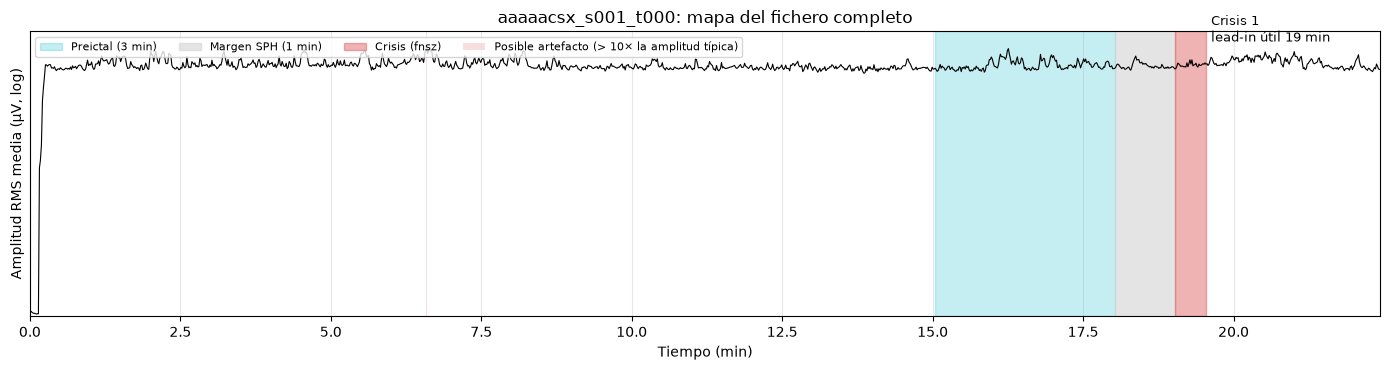

RMS mediana fuera de crisis: 7 µV | dentro de la crisis de ejemplo: 9 µV (1,2 veces)
🔴 Posible artefacto en el 0 % del fichero (0,083 min fuera de crisis con RMS > 75 µV)


In [18]:
def sombrear_periodos(ax, con_etiquetas=False):
    # Sombrea crisis, ventana preictal y margen de la crisis de ejemplo (eje X en minutos)
    ax.axvspan(t_preictal / 60, t_margen / 60, color=COLORES_PERIODO['preictal'], alpha=0.25,
               label=f'Preictal ({duracion_legible(VENTANA_PREICTAL_S)})' if con_etiquetas else None)
    ax.axvspan(t_margen / 60, t_crisis / 60, color=COLORES_PERIODO['margen'], alpha=0.6,
               label=f'Margen SPH ({duracion_legible(SPH_S)})' if con_etiquetas else None)
    for i, c in crisis.iterrows():
        ax.axvspan(c.inicio_s / 60, c.fin_s / 60, color=COLORES_ETIQUETA[c.tipo], alpha=0.35,
                   label=f'Crisis ({c.tipo})' if con_etiquetas and i == 0 else None)


# RMS por segundo, media de los 22 canales
muestras_1s = int(FS)
n_seg = senal_uv.shape[1] // muestras_1s
rms = np.sqrt((senal_uv[:, :n_seg * muestras_1s].reshape(len(tcp.ch_names), n_seg, muestras_1s) ** 2)
              .mean(axis=2)).mean(axis=0)
t_rms = np.arange(n_seg) + 0.5

en_crisis = np.zeros(len(t_rms), dtype=bool)
for _, c in crisis.iterrows():
    en_crisis |= (t_rms >= c.inicio_s) & (t_rms <= c.fin_s)
rms_fuera = np.median(rms[~en_crisis])
rms_crisis = np.median(rms[(t_rms >= t_crisis) & (t_rms <= t_fin_crisis)])

# Posible artefacto: segundos fuera de crisis con más de 10 veces la amplitud típica
UMBRAL_ARTEFACTO = 10
artefacto = (rms > UMBRAL_ARTEFACTO * rms_fuera) & ~en_crisis

fig, ax = plt.subplots(figsize=(14, 3.8))
sombrear_periodos(ax, con_etiquetas=True)
ax.fill_between(t_rms / 60, 0, 1, where=artefacto, transform=ax.get_xaxis_transform(), color='tab:red',
                alpha=0.15, linewidth=0, label=f'Posible artefacto (> {UMBRAL_ARTEFACTO}× la amplitud típica)')
ax.plot(t_rms / 60, rms, color='black', linewidth=0.8)
for i, c in crisis.iterrows():
    ax.annotate(f'Crisis {i + 1}\nlead-in útil {duracion_legible(c.leadin_util_s)}',
                xy=(c.fin_s / 60, rms.max() * 1.5), xytext=(4, 0), textcoords='offset points',
                fontsize=9, va='bottom')
ax.set_yscale('log')                     # log: se ven a la vez el fondo, la crisis y los artefactos
ax.set_ylim(rms.min() * 0.7, rms.max() * 12)
eje_log_legible(ax, 'y')
ax.set_xlim(0, tiempos[-1] / 60)
ax.set_xlabel('Tiempo (min)')
ax.set_ylabel('Amplitud RMS media (µV, log)')
ax.set_title(f'{EJEMPLO}: mapa del fichero completo')
ax.legend(loc='upper left', ncol=4, fontsize=8)
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'mapa_fichero.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'RMS mediana fuera de crisis: {rms_fuera:.0f} µV | dentro de la crisis de ejemplo: {rms_crisis:.0f} µV '
      f'({numero_legible(round(rms_crisis / rms_fuera, 1))} veces)')
if artefacto.any():
    print(f'🔴 Posible artefacto en el {artefacto.mean() * 100:.0f} % del fichero '
          f'({numero_legible(artefacto.sum() / 60)} min fuera de crisis con RMS > {UMBRAL_ARTEFACTO * rms_fuera:.0f} µV)')
else:
    print('Sin tramos de artefacto evidentes.')

## 10. Los 22 canales durante la crisis

La figura típica de un informe de EEG: los 22 canales TCP apilados, desde 10 s antes hasta 8 s después de la crisis, agrupados por cadena (separadas con una línea).

Para **leer las trazas** usamos el filtro de trazado de la sección 2, como haría un neurólogo: desaparecen las derivas lentas y buena parte de la "pelusa" muscular que engordaba las líneas.

Durante la crisis la amplitud es tan grande que los canales se pisarían. Por eso cada canal tiene un **carril** de alto proporcional a la amplitud de la crisis (unas 3 veces su RMS) y, como hacen los visores clínicos, se **recorta** si se sale de él: se pierde algún pico, pero se ve el ritmo y la sincronía.

Qué buscar (antes de la crisis, en general, actividad irregular de baja amplitud):

Los parpadeos (deflexiones lentas y aisladas en `FP1-F7`, `FP2-F8`...) se atenúan pero no desaparecen: tienen frecuencias parecidas a las de la crisis y ningún filtro los separa. Para quitarlos haría falta una técnica de separación de fuentes como **ICA**; lo valoraremos en la Fase 2.

- Inicio: cambio en unos pocos canales vecinos, no en todos a la vez.
- Durante: actividad rítmica que evoluciona (cambia de frecuencia y amplitud) y puede extenderse.
- Comparar los canales de un lado con los del otro: la asimetría es la pista de una crisis focal.

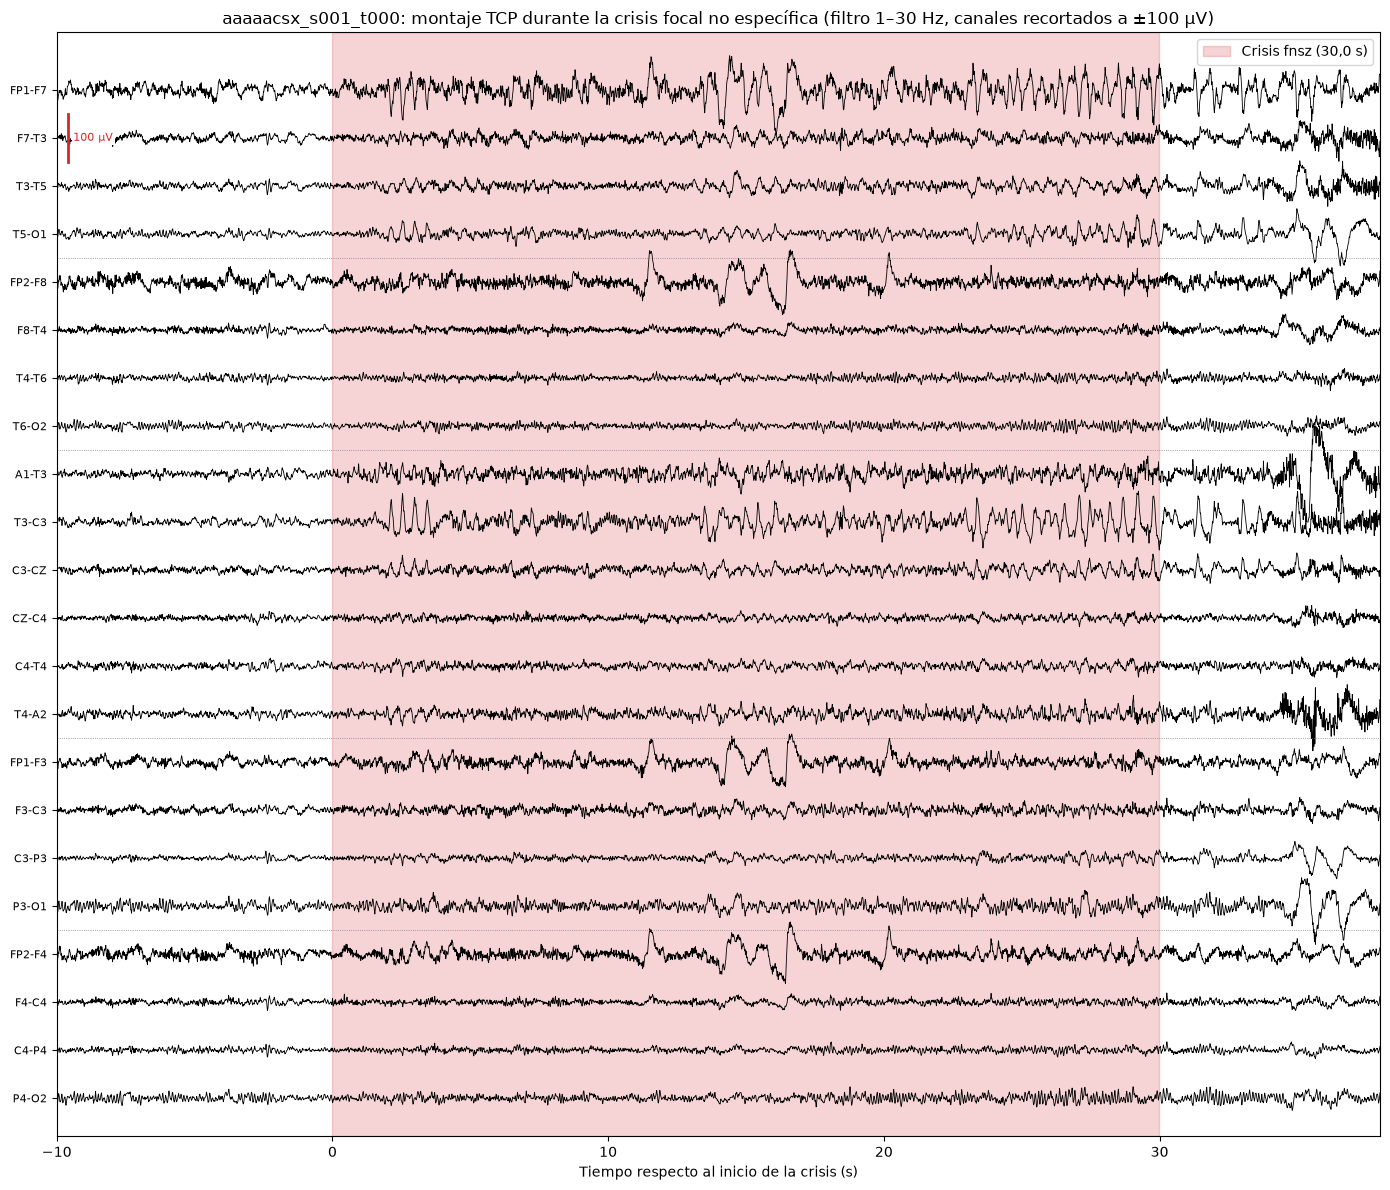

In [19]:
senal_trazado_uv = tcp.copy().notch_filter(NOTCH_HZ, verbose='error').filter(
    *FILTRO_TRAZADO_HZ, verbose='error').get_data() * 1e6


def dibujar_canales(ax, t_ini, t_fin, separacion_uv, canales=None, senal=None):
    # Dibuja los canales TCP apilados entre t_ini y t_fin (s), con el tiempo relativo al inicio de la crisis.
    # Como en los visores clínicos, cada canal se recorta a ±separación para que no pise a sus vecinos.
    canales = canales or tcp.ch_names
    senal = senal_uv if senal is None else senal
    idx = [tcp.ch_names.index(c) for c in canales]
    tramo_t = (tiempos >= t_ini) & (tiempos <= t_fin)
    for fila, i in enumerate(idx):
        recortada = np.clip(senal[i, tramo_t], -separacion_uv, separacion_uv)
        ax.plot(tiempos[tramo_t] - t_crisis, recortada - fila * separacion_uv, color='black', linewidth=0.6)
    ax.set_yticks([-fila * separacion_uv for fila in range(len(idx))])
    ax.set_yticklabels(canales, fontsize=8)
    ax.set_ylim(-(len(idx) - 0.2) * separacion_uv, separacion_uv * 1.2)
    ax.set_xlim(t_ini - t_crisis, t_fin - t_crisis)
    return canales


display(Markdown('\n'.join(f'- {punto}' for punto in INFO_TIPO['que_buscar'])))

# Alto del carril de cada canal: 3 veces la amplitud RMS de la crisis, redondeado a 50 µV
SEPARACION_UV = max(100, int(np.ceil(3 * rms_crisis / 50) * 50))
fig, ax = plt.subplots(figsize=(14, 12))
ax.axvspan(0, t_fin_crisis - t_crisis, color=COLORES_ETIQUETA[CRISIS.tipo], alpha=0.2,
           label=f'Crisis {CRISIS.tipo} ({CRISIS.duracion_s:.1f} s)'.replace('.', ','))
dibujar_canales(ax, t_crisis - 10, t_fin_crisis + 8, SEPARACION_UV, senal=senal_trazado_uv)
canales_por_cadena = [sum(f'{a}-{c}' in tcp.ch_names for a, c in pares) for pares in CADENAS_TCP.values()]
fin_cadenas = np.cumsum(canales_por_cadena)[:-1] - 0.5
for fin_cadena in fin_cadenas:                                          # separa las 5 cadenas
    ax.axhline(-fin_cadena * SEPARACION_UV, color='gray', linewidth=0.6, linestyle=':')
ax.plot([-9.6, -9.6], [-0.5 * SEPARACION_UV, -0.5 * SEPARACION_UV - 100], color='tab:red', linewidth=2)
ax.text(-9.4, -0.5 * SEPARACION_UV - 50, '100 µV', color='tab:red', fontsize=8, va='center',
        bbox=dict(facecolor='white', edgecolor='none', pad=1))
ax.set_xlabel('Tiempo respecto al inicio de la crisis (s)')
ax.set_title(f'{EJEMPLO}: montaje TCP durante la crisis {INFO_TIPO["nombre"]} '
             f'(filtro {FILTRO_TRAZADO_HZ[0]}–{FILTRO_TRAZADO_HZ[1]} Hz, canales recortados a ±{SEPARACION_UV} µV)')
ax.legend(loc='upper right')
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'crisis_22_canales.png', dpi=150, bbox_inches='tight')
plt.show()

## 11. La firma de la crisis en el espectro

Recordatorio de los periodos que comparamos (sección 3):

- **Interictal**: señal normal, lejos de la crisis. En un fichero de pocos minutos no podemos alejarnos mucho: tomamos el tramo que acaba 1 min antes de empezar el preictal.
- **Preictal**: los minutos previos a la crisis (tomamos el final de la ventana preictal, justo antes del margen).
- **Crisis**: la propia crisis.

Los tres tramos tienen la **misma duración que la crisis**, para que sean comparables.

**El espectro de Welch.** Para saber qué frecuencias tiene una señal se usa la **transformada de Fourier**, pero aplicada a un tramo entero da un espectro muy ruidoso. El **método de Welch** [7] lo arregla así:

1. Corta el tramo en **trozos cortos** (aquí de 2 s) que se solapan entre sí.
2. Calcula el espectro de cada trozo.
3. **Promedia** todos los espectros.

Al promediar, el ruido se cancela y quedan las frecuencias que de verdad están en la señal. El precio es la resolución: con trozos de 2 s se distinguen frecuencias separadas 0,5 Hz. El resultado (PSD) se mide en **µV²/Hz**: potencia por cada hercio.

- **Izquierda**: zoom de 3 s en mitad de la crisis, en los 4 canales con más amplitud **de entre los que tienen la crisis anotada** (en una crisis focal, así se ve donde está de verdad).
- **Derecha**: espectro de Welch de los tres tramos. La franja de color es el **rango típico** de este tipo de crisis según la literatura (si lo tiene).

**Frecuencia característica.** El EEG siempre tiene más potencia cuanto más baja es la frecuencia (fondo "1/f"), así que el **máximo** del espectro casi siempre cae en el extremo más lento y no dice nada de la crisis. Por eso separamos el espectro en dos partes [20]:

1. El **fondo 1/f**: en escala log-log es casi una recta. La ajustamos (línea de puntos) entre 1 y 30 Hz.
2. Los **picos** que sobresalen de esa recta: son los ritmos de verdad. La **frecuencia característica** es el pico que más sobresale (línea discontinua).

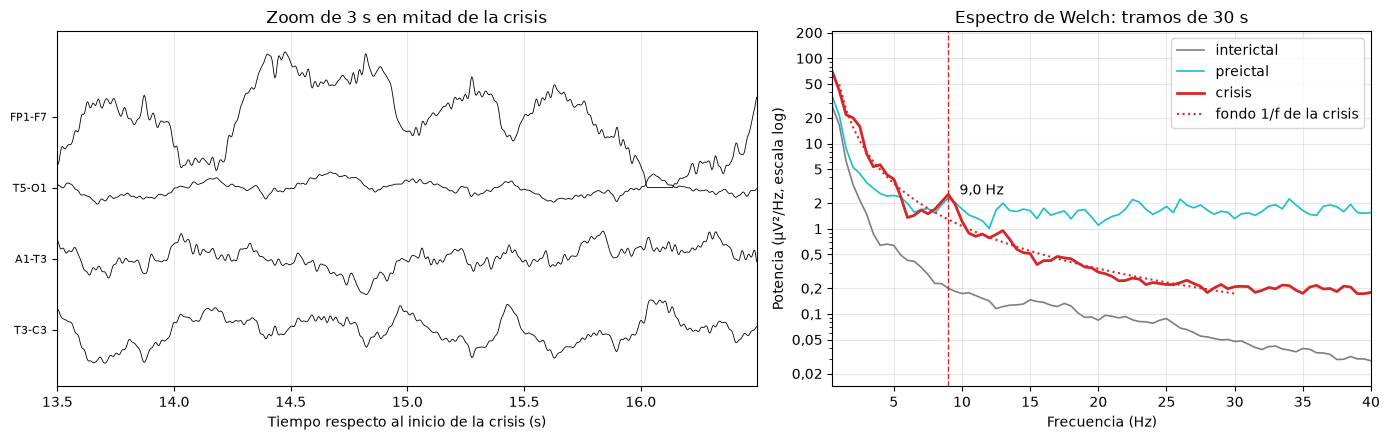

Frecuencia característica de la crisis: 9.0 Hz (🟥 fnsz (♦️) no tiene una frecuencia típica única)
Potencia a 9.0 Hz en la crisis: 13 veces la interictal


In [20]:
def espectro_medio(t_ini, t_fin):
    # Espectro de Welch (µV²/Hz) entre t_ini y t_fin, medio de los 22 canales
    tramo_t = (tiempos >= t_ini) & (tiempos < t_fin)
    frecs, psd = signal.welch(senal_uv[:, tramo_t], fs=FS, nperseg=int(2 * FS))   # trozos de 2 s
    return frecs, psd.mean(axis=0)


def fondo_1f(frecs, psd, rango=(1, 30)):
    # Recta del fondo 1/f: ajuste lineal de log10(potencia) frente a log10(frecuencia) dentro del rango.
    # Devuelve una función que da la potencia del fondo a cualquier frecuencia
    banda = (frecs >= rango[0]) & (frecs <= rango[1])
    pendiente, corte = np.polyfit(np.log10(frecs[banda]), np.log10(psd[banda]), 1)
    return lambda f: 10 ** (corte + pendiente * np.log10(f))


def frecuencia_caracteristica(frecs, psd, rango=(1, 30)):
    # Frecuencia del pico que más sobresale del fondo 1/f (mayor cociente potencia / fondo)
    banda = (frecs >= rango[0]) & (frecs <= rango[1])
    sobre_fondo = psd[banda] / fondo_1f(frecs, psd, rango)(frecs[banda])
    return frecs[banda][sobre_fondo.argmax()]


dur = CRISIS.duracion_s
# El interictal acaba 1 min antes del preictal y dura como la crisis, sin empezar antes de la crisis anterior
inicio_interictal = max(t_libre, t_preictal - 60 - dur)
assert t_preictal - 60 - inicio_interictal >= MIN_INTERICTAL_S, 'No cabe el tramo interictal en este fichero.'
tramos = {
    'interictal': (inicio_interictal, t_preictal - 60),
    'preictal': (t_margen - dur, t_margen),                     # final de la ventana preictal
    'crisis': (t_crisis, t_fin_crisis),
}
colores_tramo = {'interictal': COLORES_PERIODO['interictal'], 'preictal': COLORES_PERIODO['preictal'],
                 'crisis': COLORES_ETIQUETA[CRISIS.tipo]}
espectros = {nombre: espectro_medio(*t) for nombre, t in tramos.items()}

frecs, psd_crisis = espectros['crisis']
frec_caracteristica = frecuencia_caracteristica(frecs, psd_crisis)

fig, (ax_zoom, ax_psd) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={'width_ratios': [1.3, 1]})
centro = t_crisis + dur / 2
# Los 4 canales con más amplitud durante la crisis, de entre los que la tienen anotada
en_la_crisis = (tiempos >= t_crisis) & (tiempos < t_fin_crisis)
rms_canal = pd.Series(np.sqrt((senal_uv[:, en_la_crisis] ** 2).mean(axis=1)), index=tcp.ch_names)
canales_zoom = rms_canal[[c for c in canales_crisis if c in tcp.ch_names]].nlargest(4).index.tolist()
canales_zoom = [c for c in tcp.ch_names if c in canales_zoom]                  # en el orden del montaje
escala_zoom = int(np.ceil(2.5 * rms_canal[canales_zoom].max() / 50) * 50)       # carril de cada canal (µV)
dibujar_canales(ax_zoom, centro - 1.5, centro + 1.5, escala_zoom, canales=canales_zoom)
ax_zoom.set_xlabel('Tiempo respecto al inicio de la crisis (s)')
ax_zoom.set_title('Zoom de 3 s en mitad de la crisis')
ax_zoom.grid(True, axis='x', alpha=0.3)

for nombre, (f, p) in espectros.items():
    ax_psd.semilogy(f, p, color=colores_tramo[nombre], linewidth=2 if nombre == 'crisis' else 1.2, label=nombre)
if INFO_TIPO['rango_tipico_hz']:
    ax_psd.axvspan(*INFO_TIPO['rango_tipico_hz'], color=COLORES_ETIQUETA[CRISIS.tipo], alpha=0.12,
                   label=f'rango típico ({INFO_TIPO["nombre"]})')
frecs_fondo = frecs[(frecs >= 1) & (frecs <= 30)]
ax_psd.semilogy(frecs_fondo, fondo_1f(frecs, psd_crisis)(frecs_fondo), color=COLORES_ETIQUETA[CRISIS.tipo],
                linestyle=':', linewidth=1.5, label='fondo 1/f de la crisis')
ax_psd.axvline(frec_caracteristica, color=COLORES_ETIQUETA[CRISIS.tipo], linestyle='--', linewidth=1)
ax_psd.annotate(f'{frec_caracteristica:.1f} Hz'.replace('.', ','),
                xy=(frec_caracteristica, np.interp(frec_caracteristica, frecs, psd_crisis)),
                xytext=(8, 0), textcoords='offset points', fontsize=10)
ax_psd.set_xlim(0.5, 40)
visibles_psd = (frecs >= 0.5) & (frecs <= 40)
ax_psd.set_ylim(min(p[visibles_psd].min() for _, p in espectros.values()) * 0.5, psd_crisis.max() * 3)
eje_log_legible(ax_psd, 'y')
ax_psd.set_xlabel('Frecuencia (Hz)')
ax_psd.set_ylabel('Potencia (µV²/Hz, escala log)')
ax_psd.set_title(f'Espectro de Welch: tramos de {dur:.0f} s')
ax_psd.legend()
ax_psd.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'zoom_y_espectro.png', dpi=150, bbox_inches='tight')
plt.show()

potencia_pico = {n: np.interp(frec_caracteristica, f, p) for n, (f, p) in espectros.items()}
if INFO_TIPO['rango_tipico_hz']:
    lo_tip, hi_tip = INFO_TIPO['rango_tipico_hz']
    print(f'Frecuencia característica de la crisis: {frec_caracteristica:.1f} Hz (rango típico de '
          f'{con_icono(TIPO_CRISIS)}: {lo_tip}–{hi_tip} Hz -> {"dentro" if lo_tip <= frec_caracteristica <= hi_tip else "fuera"})')
else:
    print(f'Frecuencia característica de la crisis: {frec_caracteristica:.1f} Hz '
          f'({con_icono(TIPO_CRISIS)} no tiene una frecuencia típica única)')
print(f'Potencia a {frec_caracteristica:.1f} Hz en la crisis: {potencia_pico["crisis"] / potencia_pico["interictal"]:.0f} veces '
      f'la interictal')

In [21]:
display(Markdown(f'**Nota sobre el rango típico.** {INFO_TIPO["nota_espectro"]}'))

**Nota sobre el rango típico.** Las crisis focales no tienen una frecuencia típica única: depende de la zona y del paciente. Además, el espectro es la media de todos los canales, así que una crisis que solo afecta a unos pocos se diluye. Por eso el zoom de la izquierda usa los canales donde está anotada la crisis.

## 12. Espectrograma: de la señal normal a la crisis

Un espectro (sección 11) resume **un tramo entero**: dice qué frecuencias hay, pero no **cuándo**. El **espectrograma** añade el tiempo: calcula el espectro en ventanas cortas (2 s) que se van deslizando (cada 0,5 s) y los pone uno al lado de otro, como una partitura:

- **Eje X**: tiempo. **Eje Y**: frecuencia. **Color**: potencia, en **decibelios** (dB, escala logarítmica: +10 dB = 10 veces más potencia).

Cubre desde 1 min antes de la ventana preictal hasta 1 min después de la crisis (media de los 22 canales, 0,5–45 Hz). Las líneas discontinuas marcan los límites de las bandas.

Es la figura que mejor resume la Fase 3: el modelo de predicción tendrá que distinguir la franja **preictal** (cian) de la **interictal** (gris), *antes* de que aparezca la crisis.

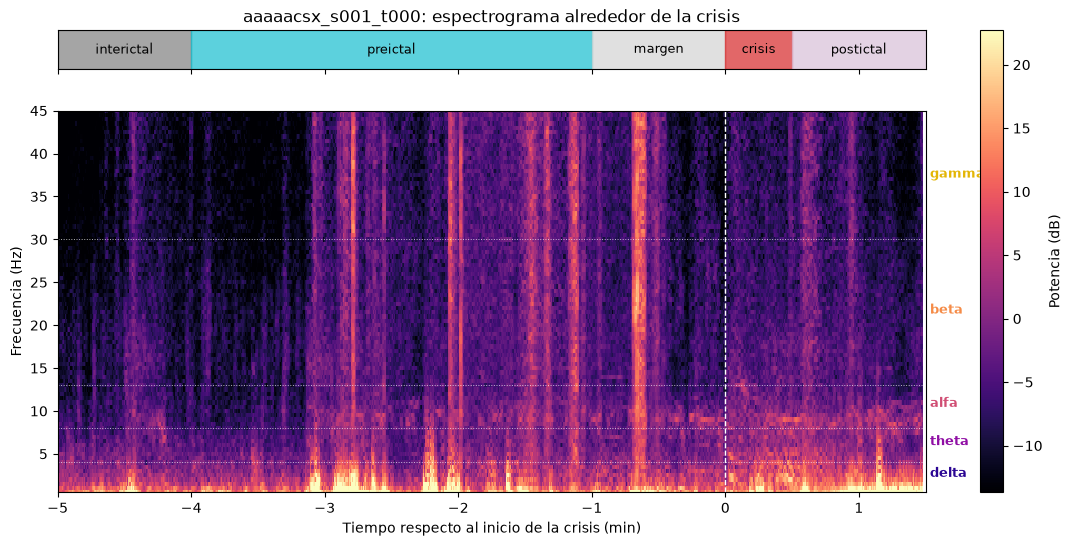

In [22]:
t_ini_esp, t_fin_esp = max(0, t_preictal - 60), min(tiempos[-1], t_fin_crisis + 60)
tramo_esp = (tiempos >= t_ini_esp) & (tiempos < t_fin_esp)
frecs_e, t_e, sxx = signal.spectrogram(senal_bandas_uv[:, tramo_esp], fs=FS, nperseg=int(2 * FS),
                                       noverlap=int(1.5 * FS))     # ventanas de 2 s cada 0,5 s
sxx_db = 10 * np.log10(sxx.mean(axis=0) + 1e-12)                  # media de los 22 canales, en dB
t_e = (t_e + t_ini_esp - t_crisis) / 60                            # minutos respecto a la crisis
visibles = (frecs_e >= 0.5) & (frecs_e <= 45)

fig, (ax_per, ax_esp) = plt.subplots(2, 1, figsize=(14, 6), sharex=True,
                                     gridspec_kw={'height_ratios': [0.1, 1]})
# Barra de periodos
for (a, b), nombre, color in [((t_ini_esp, t_preictal), 'interictal', COLORES_PERIODO['interictal']),
                              ((t_preictal, t_margen), 'preictal', COLORES_PERIODO['preictal']),
                              ((t_margen, t_crisis), 'margen', COLORES_PERIODO['margen']),
                              ((t_crisis, t_fin_crisis), 'crisis', COLORES_ETIQUETA[CRISIS.tipo]),
                              ((t_fin_crisis, t_fin_esp), 'postictal', COLORES_PERIODO['postictal'])]:
    ax_per.axvspan((a - t_crisis) / 60, (b - t_crisis) / 60, color=color, alpha=0.7)
    ax_per.text(((a + b) / 2 - t_crisis) / 60, 0.5, nombre, ha='center', va='center', fontsize=9)
ax_per.set_yticks([])
ax_per.set_title(f'{EJEMPLO}: espectrograma alrededor de la crisis')

malla = ax_esp.pcolormesh(t_e, frecs_e[visibles], sxx_db[visibles], shading='auto', cmap='magma',
                          vmin=np.percentile(sxx_db[visibles], 5), vmax=np.percentile(sxx_db[visibles], 99.5))
for banda, (lo, hi) in BANDAS_HZ.items():
    ax_esp.axhline(hi, color='white', linestyle=':', linewidth=0.7, alpha=0.7)
    ax_esp.text(1.005, (lo + hi) / 2 / 45, banda, transform=ax_esp.transAxes, fontsize=9, va='center',
                color=COLORES_BANDA[banda], fontweight='bold')
ax_esp.axvline(0, color='white', linestyle='--', linewidth=1)
ax_esp.set_xlim((t_ini_esp - t_crisis) / 60, (t_fin_esp - t_crisis) / 60)
ax_esp.set_ylim(0.5, 45)
ax_esp.set_xlabel('Tiempo respecto al inicio de la crisis (min)')
ax_esp.set_ylabel('Frecuencia (Hz)')
fig.colorbar(malla, ax=[ax_per, ax_esp], label='Potencia (dB)', pad=0.05)
fig.savefig(RUTA_FIGURAS / 'espectrograma_crisis.png', dpi=150, bbox_inches='tight')
plt.show()

## 13. Potencia por bandas a lo largo del fichero

Una forma sencilla de resumir el EEG es la **potencia por banda**: cuánta energía hay en delta, theta, alfa, beta y gamma. Es una de las entradas clásicas de los modelos de crisis.

**¿Por qué potencia relativa y no absoluta?** La potencia absoluta (µV²) depende de cosas que no tienen que ver con el cerebro: lo bien pegado que está cada electrodo, el grosor del cráneo, el amplificador o el paciente. Además, en la crisis la amplitud se multiplica varias veces (sección 9) y **todas** las bandas suben a la vez, lo que tapa los cambios de reparto. La **potencia relativa** (% de la potencia total) elimina ese factor de escala y responde a otra pregunta: **¿cómo se reparte la energía entre las bandas?** Así se pueden comparar momentos, ficheros y pacientes distintos.

Cálculo, paso a paso (comentado en el código):

1. Cortar la señal en **ventanas de 2 s**.
2. Calcular el **espectro de Welch** de cada ventana y cada canal.
3. **Sumar** la potencia de las frecuencias de cada banda.
4. **Dividir** por la suma de las cinco bandas → porcentaje.
5. **Suavizar** con una media móvil de 30 s para ver la tendencia.

Usamos la señal sin el corte de 40 Hz (`senal_bandas_uv`) para que gamma esté completa.

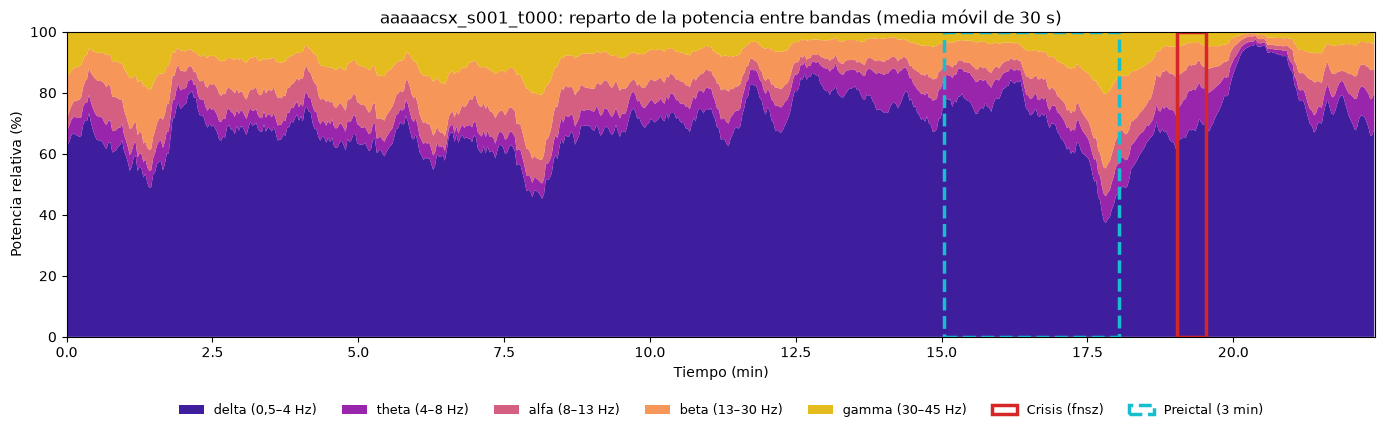

,interictal,preictal,crisis
banda (%),,,
delta,76.4,68.2,67.7
theta,7.9,7.1,13.0
alfa,4.3,5.2,8.2
beta,7.9,11.3,7.4
gamma,3.5,8.2,3.7


In [23]:
VENTANA_S = 2
muestras_v = int(VENTANA_S * FS)                       # 2 s × 250 Hz = 500 muestras por ventana
n_v = senal_bandas_uv.shape[1] // muestras_v           # nº de ventanas completas del fichero

# 1. Cortar en ventanas: (22 canales, muestras) -> (22 canales, n_v ventanas, 500 muestras)
ventanas = senal_bandas_uv[:, :n_v * muestras_v].reshape(len(tcp.ch_names), n_v, muestras_v)

# 2. Espectro de Welch de cada ventana: psd_v tiene forma (canales, ventanas, frecuencias)
frecs_v, psd_v = signal.welch(ventanas, fs=FS, nperseg=muestras_v, axis=-1)

# 3. Potencia de cada banda: suma de las frecuencias de la banda (eje -1),
#    y media de los 22 canales (eje 0). Resultado: una columna por banda, una fila por ventana
potencia = pd.DataFrame({b: psd_v[..., (frecs_v >= lo) & (frecs_v < hi)].sum(axis=-1).mean(axis=0)
                         for b, (lo, hi) in BANDAS_HZ.items()})

# 4. Potencia relativa: cada banda dividida por la suma de las cinco (fila a fila), en %
relativa = potencia.div(potencia.sum(axis=1), axis=0) * 100
relativa.index = (np.arange(n_v) + 0.5) * VENTANA_S    # tiempo del centro de cada ventana (s)

# 5. Suavizado: media móvil de 15 ventanas × 2 s = 30 s
suavizada = relativa.rolling(15, center=True, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.stackplot(suavizada.index / 60, suavizada.T.values, colors=[COLORES_BANDA[b] for b in BANDAS_HZ],
             labels=[f'{b} ({numero_legible(lo)}–{hi} Hz)' for b, (lo, hi) in BANDAS_HZ.items()], alpha=0.9)
for i, c in crisis.iterrows():                          # marca de las crisis
    ax.axvspan(c.inicio_s / 60, c.fin_s / 60, facecolor='none', edgecolor=COLORES_ETIQUETA[c.tipo],
               linewidth=2.5, label=f'Crisis ({c.tipo})' if i == 0 else None)
ax.axvspan(t_preictal / 60, t_margen / 60, facecolor='none', edgecolor=COLORES_PERIODO['preictal'],
           linewidth=2.5, linestyle='--', label=f'Preictal ({duracion_legible(VENTANA_PREICTAL_S)})')
ax.set_xlim(0, tiempos[-1] / 60)
ax.set_ylim(0, 100)
ax.set_xlabel('Tiempo (min)')
ax.set_ylabel('Potencia relativa (%)')
ax.set_title(f'{EJEMPLO}: reparto de la potencia entre bandas (media móvil de 30 s)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=7, fontsize=9, frameon=False)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'potencia_por_bandas.png', dpi=150, bbox_inches='tight')
plt.show()


def media_periodo(a, b):
    # Potencia relativa media (sin suavizar) de las ventanas cuyo centro cae entre a y b (s)
    return relativa[(relativa.index >= a) & (relativa.index < b)].mean()


comparacion = pd.DataFrame({
    'interictal': media_periodo(max(t_libre, t_preictal - 3 * 60), t_preictal),
    'preictal': media_periodo(t_preictal, t_margen),
    'crisis': media_periodo(t_crisis, t_fin_crisis),
}).round(1)
comparacion.index.name = 'banda (%)'
display(comparacion.style.format('{:.1f}').apply(
    lambda fila: [f'border-left: 14px solid {COLORES_BANDA[fila.name]}'] + [''] * (len(fila) - 1), axis=1))

👀 **Cómo leer la figura.** Eje X: el fichero completo, en minutos. Cada color es una banda y su altura, el **% de la potencia** en ese momento (siempre suman 100 %). Los recuadros marcan la crisis (línea continua) y el preictal (discontinua). Busca **qué banda gana terreno dentro del recuadro de la crisis** y si algo cambia ya en el preictal. La tabla de debajo da las medias de cada periodo.

## 14. ¿Dónde se origina la crisis?

Hasta aquí hemos visto **cuándo** hay crisis y **cómo** es. Ahora, **dónde arranca**. Tres figuras, de lo más directo a lo más elaborado:

1. **El arranque canal a canal** (estilo SEEG): qué canales TCP crecen más en los primeros segundos.
2. **Vista desde arriba**: el mapa del cuero cabelludo junto al cerebro visto desde arriba.
3. **El cerebro en 3D**: el origen estimado, visto desde los cuatro lados.

Las tres comparan los **primeros segundos de la crisis** (`VENTANA_INICIO_S`) con un **tramo basal** de señal normal (interictal, hasta 2 min antes del preictal, como en la sección 11). La medida es el **aumento de potencia en decibelios**: +10 dB = 10 veces más potencia que en el basal; 0 dB = sin cambio.

**⚠️ Limitaciones (decirlas siempre que se enseñen estas figuras):**

- El cerebro es una **plantilla** (*fsaverage*, la media de 40 personas [22]): TUSZ no trae la resonancia de cada paciente.
- Con unos **19 electrodos** la precisión es de **lóbulo**, no de centímetros [25].
- El inicio anotado en TUSZ puede ir algún segundo tarde o temprano respecto al arranque real.

Es una **visualización orientativa**, no un diagnóstico. Sirve, sobre todo, como **comprobación de las etiquetas**: una crisis focal (🟥 `fnsz` (♦️)) debería encenderse en una zona, y una generalizada o una ausencia (🟩 `absz` (🔹)), en casi todo el cerebro.

**Qué hace falta.** Lo dice la tabla de requisitos de la sección 1: `nibabel` para el cerebro plantilla y `pyvista`, `pyvistaqt` y `pyqt6` para el 3D.

**Tiempos.** La primera vez se descarga el cerebro plantilla de MNE (unos 200 MB, en la carpeta `mne_data` del usuario) y se calcula el **modelo de la cabeza** (1-2 min). El modelo se guarda en `outputs/comun/modelos_cabeza/` y se reutiliza: las siguientes ejecuciones, con los mismos electrodos, tardan segundos.

### 14.1. El arranque canal a canal (estilo SEEG)

Los canales TCP con más aumento de potencia en los primeros segundos de la crisis, como se presentan los registros de electrodos intracraneales.

Python      3.14.0
pyvista     0.49.2
Inicio de la crisis: 1142.1–1147.1 s  |  basal: 722.1–842.1 s (2 min)


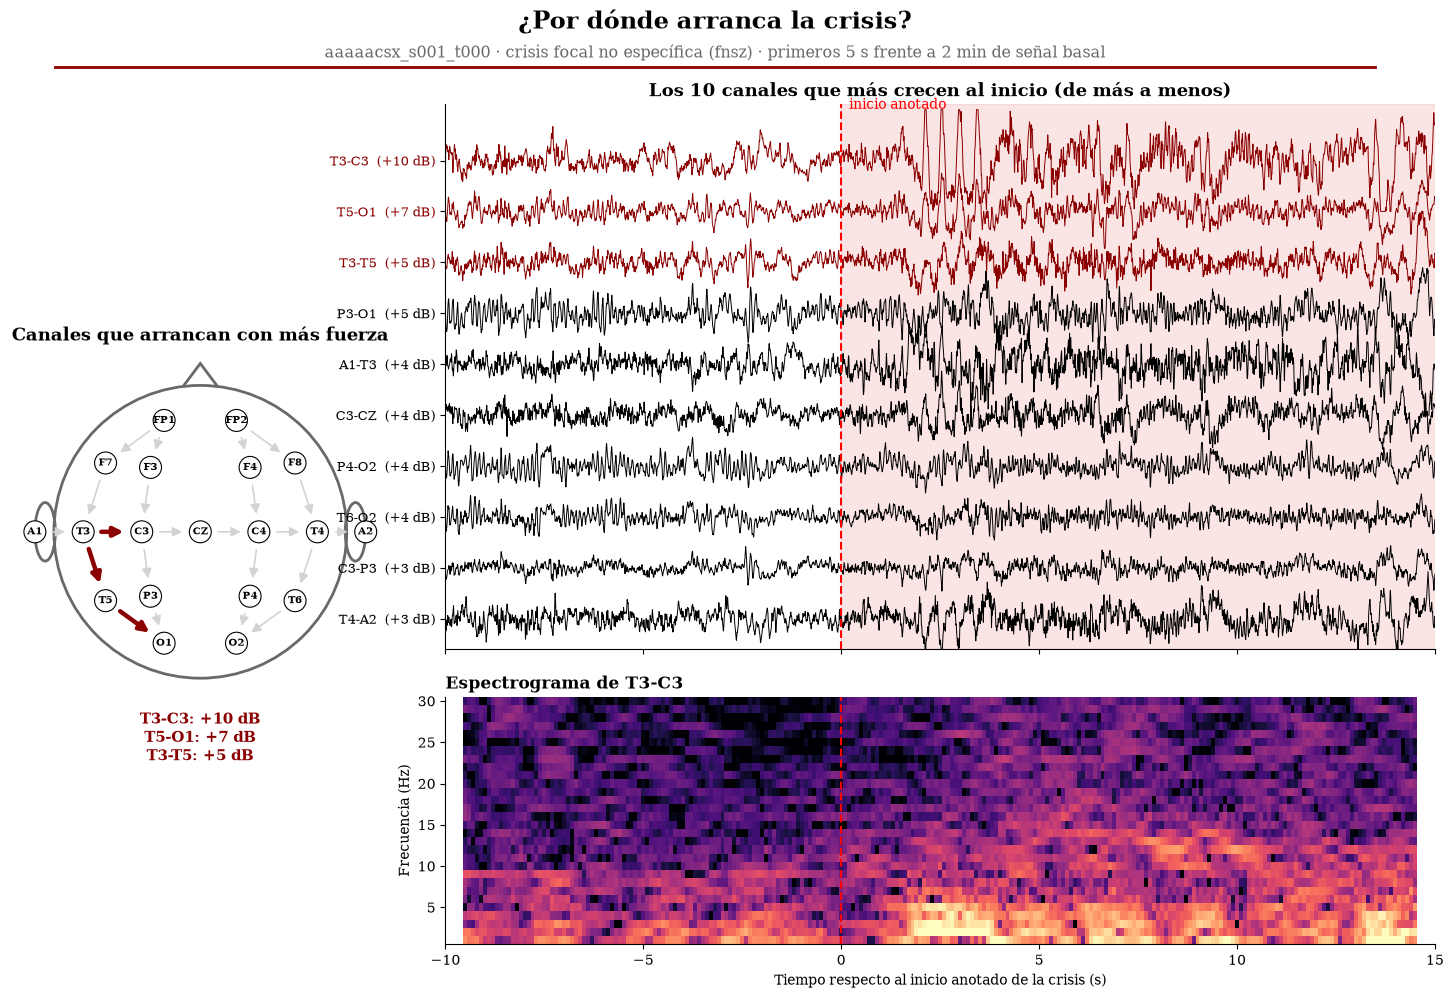

Canales líder: T3-C3, T5-O1, T3-T5  ->  2 de 3 están entre los 5 canales donde TUSZ anota la crisis


In [24]:
from tfm_comun.entorno.rutas import RUTA_MODELOS_CABEZA
from tfm_comun.senal.fuentes import origen_crisis, resumen_por_region, BANDA_FUENTES_HZ, METODO_INVERSO
from tfm_comun.visual.inicio_crisis import aumento_por_canal, figura_inicio_crisis
from tfm_comun.visual.cerebro import (limites_color, capturas_cerebro, abrir_cerebro_interactivo,
                                      figura_cerebro_3d, figura_desde_arriba)

# Parámetros de la sección
VENTANA_INICIO_S = 5          # primeros segundos de la crisis que se comparan con el basal
BASAL_MAXIMO_S = 120          # señal basal: hasta 2 min, acabando 1 min antes del preictal (como en la sección 11)
N_CANALES_LIDER = 3           # canales que se resaltan en rojo
CEREBRO_INTERACTIVO = True   # True: abre además una ventana para girar el cerebro con el ratón (solo a mano)

# ¿Está instalado lo necesario para el 3D? (comprobado en la sección 1 con requisitos.py)
HAY_3D = all(disponibles[m] for m in ('pyvista', 'pyvistaqt', 'PyQt6'))
if HAY_3D:
    import pyvista
    config['versiones'].update(mostrar_versiones(pyvista))
else:
    print('🔴 Falta el 3D (ver la tabla de requisitos de la sección 1): se calculan los datos y la figura '
          'del arranque, pero no el cerebro.')

# Tramos que se comparan (segundos desde el inicio del fichero)
tramo_inicio = (t_crisis, t_crisis + min(VENTANA_INICIO_S, CRISIS.duracion_s))
tramo_basal = (max(t_libre, t_preictal - 60 - BASAL_MAXIMO_S), t_preictal - 60)
assert tramo_basal[1] - tramo_basal[0] >= MIN_INTERICTAL_S, 'No cabe un tramo basal en este fichero.'
print(f'Inicio de la crisis: {tramo_inicio[0]:.1f}–{tramo_inicio[1]:.1f} s  |  '
      f'basal: {tramo_basal[0]:.1f}–{tramo_basal[1]:.1f} s ({duracion_legible(tramo_basal[1] - tramo_basal[0])})')

# Aumento de potencia en cada canal TCP (señal 0,5–40 Hz de la sección 8)
aumento_tcp = aumento_por_canal(senal_uv, tiempos, tcp.ch_names, tramo_basal, tramo_inicio)
canales_lider = sorted(aumento_tcp, key=aumento_tcp.get, reverse=True)[:N_CANALES_LIDER]
subtitulo = (f'{EJEMPLO} · crisis {INFO_TIPO["nombre"]} ({TIPO_CRISIS}) · primeros {numero_legible(tramo_inicio[1] - tramo_inicio[0])} s '
             f'frente a {duracion_legible(tramo_basal[1] - tramo_basal[0])} de señal basal')

fig = figura_inicio_crisis(senal_uv, tiempos, FS, tcp.ch_names, aumento_tcp, canales_lider, t_crisis, t_fin_crisis,
                           COLORES_ETIQUETA[CRISIS.tipo], '¿Por dónde arranca la crisis?', subtitulo)
fig.savefig(RUTA_FIGURAS / 'origen_1_arranque_canales.png', dpi=150, bbox_inches='tight')
plt.show()

anotados = [c for c in canales_lider if c in canales_crisis]
print(f'Canales líder: {", ".join(canales_lider)}  ->  {len(anotados)} de {len(canales_lider)} '
      f'están entre los {n_canales_crisis} canales donde TUSZ anota la crisis')

👀 **Cómo leer la figura.** Es la composición típica de los registros de SEEG (electrodos dentro del cerebro) [26], hecha aquí con los canales de superficie:

- **Izquierda**: la cabeza con los 22 canales TCP como flechas; en **rojo**, los que más crecen al inicio (con su aumento en dB debajo).
- **Derecha arriba**: los 10 canales que más crecen, de más a menos. La línea roja discontinua es el **inicio anotado** y el sombreado, la crisis. Fíjate en qué canales cambian **antes** o **con más fuerza**.
- **Derecha abajo**: el espectrograma del canal que más crece (escala de color en dB, como en la sección 12): se ve aparecer la frecuencia de la crisis.

Si los canales rojos están **juntos en un lado** de la cabeza, la crisis es probablemente focal; si están **repartidos** y todos crecen parecido, generalizada.

### 14.2. Origen estimado dentro del cerebro (sLORETA)

Los electrodos miden en la **superficie**; lo que queremos saber pasa **dentro**. Estimarlo se llama **localización de fuentes** [24] y se hace en tres pasos (`tfm_comun/senal/fuentes.py`):

1. **Problema directo.** Con un modelo de la cabeza (cerebro, cráneo y cuero cabelludo) se calcula qué vería cada electrodo si se activara cada uno de los ~20.000 puntos de la corteza del cerebro plantilla.
2. **Problema inverso.** Se recorre el camino al revés: de lo que miden los electrodos a la actividad de cada punto. Usamos **sLORETA** [21], que da la solución más suave y con poco error de localización. Para separar señal de ruido usa la covarianza del **tramo basal**.
3. **Comparación.** Potencia de cada punto en los primeros segundos de la crisis entre su potencia en el basal, en dB.

Después se traduce a **regiones con nombre** con el atlas de Desikan-Killiany [23] (`tfm_comun/dataset/regiones_cerebro.py`): qué giro y qué lóbulo crecen más. Solo se pintan los puntos que crecen al menos el **60 % del máximo**: en una crisis focal se enciende una zona pequeña y en una generalizada casi todo.

In [25]:
# Origen estimado: electrodos ruidosos fuera (sección 8)
inicio_calculo = time.time()
# El modelo de la cabeza se guarda la primera vez y se reutiliza (RUTA_MODELOS_CABEZA)
origen = origen_crisis(raw, tramo_basal, tramo_inicio, excluir=list(ruidosos.index), notch_hz=NOTCH_HZ,
                       carpeta_modelos=RUTA_MODELOS_CABEZA)
limites = limites_color(origen['cociente_db'])
maximo, lobulos = resumen_por_region(origen['cociente_db'], origen['vertices'], origen['subjects_dir'],
                                     limites['fmin'])
print(f'Cálculo: {time.time() - inicio_calculo:.0f} s  |  {len(origen["electrodos_db"])} electrodos '
      f'({", ".join(origen["electrodos_db"].index)})  |  {len(origen["cociente_db"]):,} puntos de la corteza'.replace(',', '.'))

config['localizacion'] = {'metodo': METODO_INVERSO, 'banda_hz': BANDA_FUENTES_HZ, 'ventana_inicio_s': VENTANA_INICIO_S,
                          'tramo_inicio_s': [round(t, 2) for t in tramo_inicio],
                          'tramo_basal_s': [round(t, 2) for t in tramo_basal],
                          'electrodos': list(origen['electrodos_db'].index), 'maximo': maximo}
with open(RUTA_RESULTADOS / 'configuracion.json', 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=4, ensure_ascii=False, default=float)

lobulos.reset_index().to_csv(RUTA_RESULTADOS / 'origen_por_lobulo.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'origen_por_lobulo.csv',
                'una fila por lóbulo y hemisferio: cuánto crece la potencia al inicio de la crisis respecto al basal '
                '(media y máximo, en dB) y qué % de sus puntos supera el umbral de la figura; ordenado de más a menos')

# Resumen: dónde está el máximo, de qué lado y cómo de repartido
por_lado = lobulos.groupby('hemisferio')['aumento medio (dB)'].mean()
diferencia_lados = por_lado.get('derecho', 0) - por_lado.get('izquierdo', 0)
lado = ('derecho' if diferencia_lados > 0 else 'izquierdo') if abs(diferencia_lados) >= 1 else None
activos = 100 * (origen['cociente_db'] >= limites['fmin']).mean()
reparto = 'localizada' if activos < 15 else 'intermedia' if activos < 35 else 'repartida'
esperado = {'focal': 'localizada', 'generalizada': 'repartida', 'ausencia': 'repartida'}[grupo(TIPO_CRISIS)]
display(Markdown(f'''**En este ejemplo** ({con_icono(TIPO_CRISIS)}):

- **Máximo** en el **{maximo["región"]}** (lóbulo {maximo["lóbulo"]}, hemisferio {maximo["hemisferio"]}), con **+{numero_legible(maximo["aumento (dB)"])} dB**.
- **Lado**: {f"predomina el hemisferio **{lado}** ({numero_legible(abs(diferencia_lados))} dB más de media)" if lado else "los dos hemisferios crecen parecido (menos de 1 dB de diferencia)"}.
- **Reparto**: el **{numero_legible(activos)} %** de la corteza supera el umbral → actividad **{reparto}**. Para una crisis {grupo(TIPO_CRISIS)} ({ICONO_GRUPO[grupo(TIPO_CRISIS)]}) se esperaría {esperado} → {"✅ encaja" if reparto == esperado else "⚠️ no encaja del todo: revisar artefactos o el inicio anotado"}.
- Electrodo que más crece en el cuero cabelludo: **{origen["electrodos_db"].idxmax()}** (+{numero_legible(origen["electrodos_db"].max())} dB).'''))

Cálculo: 2 s  |  19 electrodos (FP1. FP2. F3. F4. C3. C4. P3. P4. O1. O2. F7. F8. T3. T4. T5. T6. FZ. CZ. PZ)  |  20.484 puntos de la corteza


💾 **Guardado `origen_por_lobulo.csv`** · 459 B · 12 filas × 5 columnas  
*Qué guarda:* una fila por lóbulo y hemisferio: cuánto crece la potencia al inicio de la crisis respecto al basal (media y máximo, en dB) y qué % de sus puntos supera el umbral de la figura; ordenado de más a menos. *Abajo:* las 5 primeras filas.

,lóbulo,hemisferio,aumento medio (dB),aumento máximo (dB),% puntos activos
0,ínsula,izquierdo,7.3,11.3,63.9
1,temporal,izquierdo,7.3,11.3,68.7
2,occipital,izquierdo,5.9,11.6,36.5
3,cíngulo,izquierdo,5.8,8.7,40.0
4,parietal,izquierdo,5.4,11.4,25.7


**En este ejemplo** (🟥 fnsz (♦️)):

- **Máximo** en el **giro lingual** (lóbulo occipital, hemisferio izquierdo), con **+11,6 dB**.
- **Lado**: predomina el hemisferio **izquierdo** (3,0 dB más de media).
- **Reparto**: el **21,4 %** de la corteza supera el umbral → actividad **intermedia**. Para una crisis focal (♦️) se esperaría localizada → ⚠️ no encaja del todo: revisar artefactos o el inicio anotado.
- Electrodo que más crece en el cuero cabelludo: **T3** (+9,2 dB).

👀 **Cómo leer la tabla.** Cada fila es un lóbulo de un hemisferio. `aumento medio (dB)` dice cuánto crece la potencia de media en ese lóbulo al inicio de la crisis; `% puntos activos`, qué parte del lóbulo se pinta en las figuras. En una crisis focal arriba debería haber uno o dos lóbulos del **mismo lado** muy por encima del resto; en una generalizada, los valores son parecidos en todos.

### 14.3. Vista desde arriba

Dos maneras de ver lo mismo desde arriba (nariz hacia arriba), con la misma regla de color: **gris** = por debajo del 60 % del máximo, y por encima de **amarillo** a **rojo oscuro** = lo que más crece (el foco). Cada mapa tiene su propio máximo, porque miden cosas distintas (electrodos y puntos del cerebro).

- **Izquierda**: el **cuero cabelludo** (*topomap*). Cada punto negro es un electrodo con su aumento, y el color se interpola entre ellos. Es **lo que se mide**.
- **Derecha**: el **cerebro** visto desde arriba con el origen **estimado** por sLORETA. Igual que en la cabeza, lo que queda por debajo del umbral se ve gris.

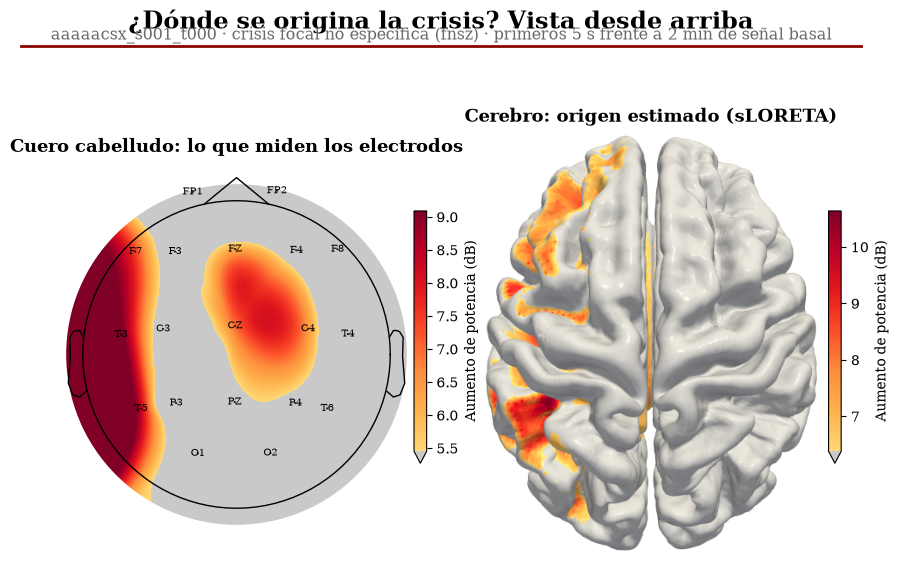

In [26]:
if HAY_3D:
    capturas = capturas_cerebro(origen, limites)
    fig = figura_desde_arriba(origen, capturas['arriba'], limites, '¿Dónde se origina la crisis? Vista desde arriba',
                              subtitulo)
    fig.savefig(RUTA_FIGURAS / 'origen_2_vista_desde_arriba.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('🔴 Sin el 3D: no se dibuja el cerebro (ver la tabla de requisitos de la sección 1).')

👀 **Cómo leer la figura.** Si la mancha roja de la cabeza (izquierda) y la del cerebro (derecha) caen en la **misma zona**, el origen estimado es coherente con lo medido. El cerebro suele dar una mancha más concentrada, porque sLORETA "deshace" la difuminación que produce el cráneo. Las dos vistas tienen la nariz hacia arriba y el hemisferio izquierdo a la izquierda (`VISTAS` en `tfm_comun/visual/cerebro.py`).

### 14.4. El cerebro en 3D

El mismo origen estimado, visto desde los cuatro lados. Es la figura más vistosa, pero también la que más **cuidado** pide al enseñarla: es un cerebro plantilla y la precisión es de lóbulo (ver las limitaciones al principio de la sección).

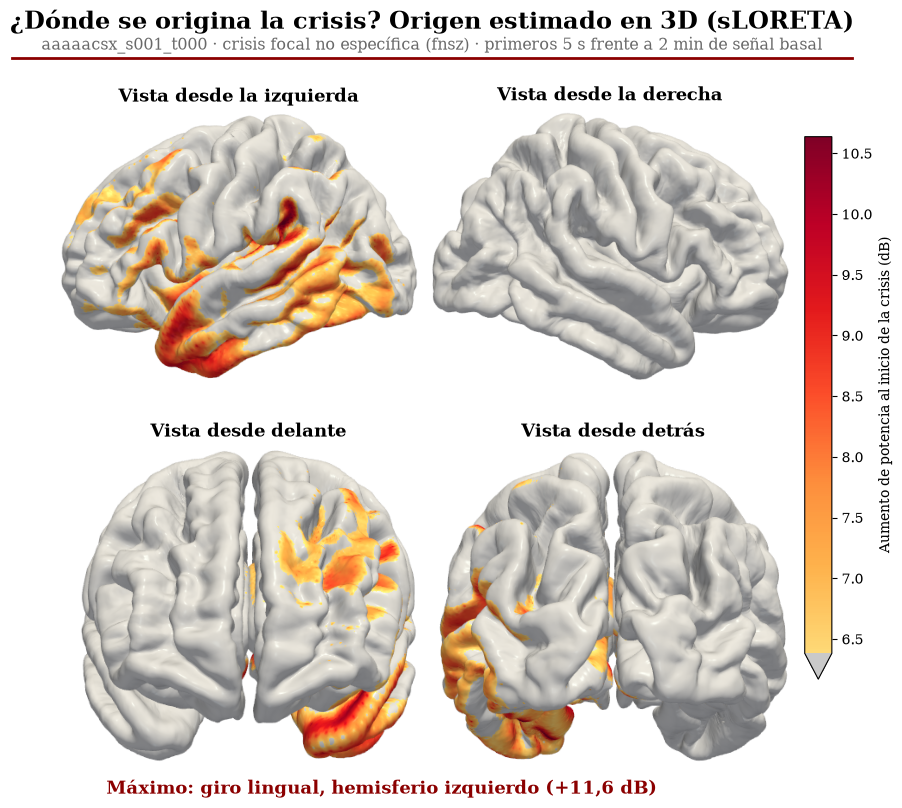

Widget(value='<iframe src="http://localhost:61134/index.html?ui=P_0x25d7a71bed0_0&reconnect=auto" class="pyvis…

In [27]:
if HAY_3D:
    texto_maximo = f'{maximo["región"]}, hemisferio {maximo["hemisferio"]} (+{numero_legible(maximo["aumento (dB)"])} dB)'
    fig = figura_cerebro_3d(capturas, limites, '¿Dónde se origina la crisis? Origen estimado en 3D (sLORETA)',
                            subtitulo, region_maxima=texto_maximo)
    fig.savefig(RUTA_FIGURAS / 'origen_3_cerebro_3d.png', dpi=150, bbox_inches='tight')
    plt.show()
    if CEREBRO_INTERACTIVO:
        cerebro_interactivo = abrir_cerebro_interactivo(origen, limites)   # ventana aparte: girar con el ratón
else:
    print('🔴 Sin el 3D: no se dibuja el cerebro (ver la tabla de requisitos de la sección 1).')

👀 **Cómo leer la figura.** Gris = la corteza que no destaca (por debajo del 60 % del máximo); de amarillo a **rojo oscuro**, cuánto crece: lo más rojo es el foco. Es la misma escala que la vista desde arriba (14.3). El pie dice la región del máximo. Lo que importa no es el punto exacto, sino **el lóbulo, el lado y el tamaño de la mancha**: pequeña y de un lado en una crisis focal; grande y en los dos hemisferios en una generalizada. Con `CEREBRO_INTERACTIVO = True` se abre además una ventana para girar el cerebro con el ratón.

## 15. Conclusiones

Cada conclusión va con una figura, las **cifras de este ejemplo** (calculadas en la celda, no escritas a mano, para que valgan para cualquier tipo de crisis) y lo que dice la literatura.

### 15.1. La lectura y el montaje funcionan

- De todas las señales del EDF solo entran en el montaje los electrodos 10-20 (🧠 `eeg`). El resto (🫀 ECG, 👁️ EOG, ❔ electrodos especiales y canales sin uso, 💡 `PHOTIC`) se descarta.
- Las mismas funciones (`tfm_comun/dataset/edf.py`, `canales.py`, `anotaciones.py`, `montaje.py`) servirán en la Fase 2 para los 8.140 ficheros, con cualquier referencia (`-LE` o `-REF`).
- **Literatura**: TUSZ trae una mezcla de referencias (AR y LE) y el propio equipo de Temple recomienda trabajar en TCP para que todos los ficheros sean comparables y encajen con las anotaciones [1, 5, 6]. La mayoría de trabajos de detección sobre TUSZ usan este montaje de 22 canales.

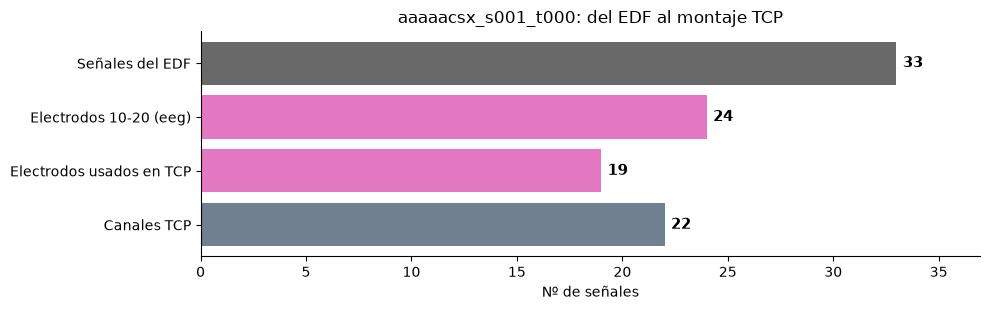

**En este ejemplo** (`aaaaacsx_s001_t000`, referencia `-LE`):

- El EDF trae **33 señales**, de las que **24** son electrodos 10-20.
- El montaje TCP sale con **22 canales** a partir de **19 electrodos**. No se usan: `FZ`, `PZ`, `OZ`, `T1`, `T2`.
- La comprobación `FP1-F7 = FP1 - F7` es exacta (error máximo 0e+00 V).

In [28]:
pasos = pd.Series({
    'Señales del EDF': len(raw.ch_names),
    'Electrodos 10-20 (eeg)': len(electrodos),
    'Electrodos usados en TCP': len(electrodos_tcp),
    'Canales TCP': len(tcp.ch_names),
})
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.barh(pasos.index[::-1], pasos.values[::-1],
        color=['slategray', COLORES_TIPO_CANAL['eeg'], COLORES_TIPO_CANAL['eeg'], 'dimgray'])
for y, valor in enumerate(pasos.values[::-1]):
    ax.text(valor + 0.3, y, str(valor), va='center', fontsize=11, fontweight='bold')
ax.set_xlim(0, pasos.max() * 1.12)
ax.set_xlabel('Nº de señales')
ax.set_title(f'{EJEMPLO}: del EDF al montaje TCP')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'conclusion_1_del_edf_al_tcp.png', dpi=150, bbox_inches='tight')
plt.show()

sin_usar = [e for e in electrodos if e not in electrodos_tcp]
display(Markdown(f'''**En este ejemplo** (`{EJEMPLO}`, referencia `-{referencia}`):

- El EDF trae **{len(raw.ch_names)} señales**, de las que **{len(electrodos)}** son electrodos 10-20.
- El montaje TCP sale con **{len(tcp.ch_names)} canales** a partir de **{len(electrodos_tcp)} electrodos**. No se usan: {", ".join(f"`{e}`" for e in sin_usar) or "ninguno"}.
- La comprobación `FP1-F7 = FP1 - F7` es exacta (error máximo {np.abs(diferencia).max():.0e} V).'''))

### 15.2. La firma de la crisis

Resumen de lo visto en las secciones 9 a 12: dónde aparece la crisis, cuánto crece la amplitud y en qué frecuencia. La figura repite las medidas para **todas las crisis del fichero**, para ver si el patrón se repite.

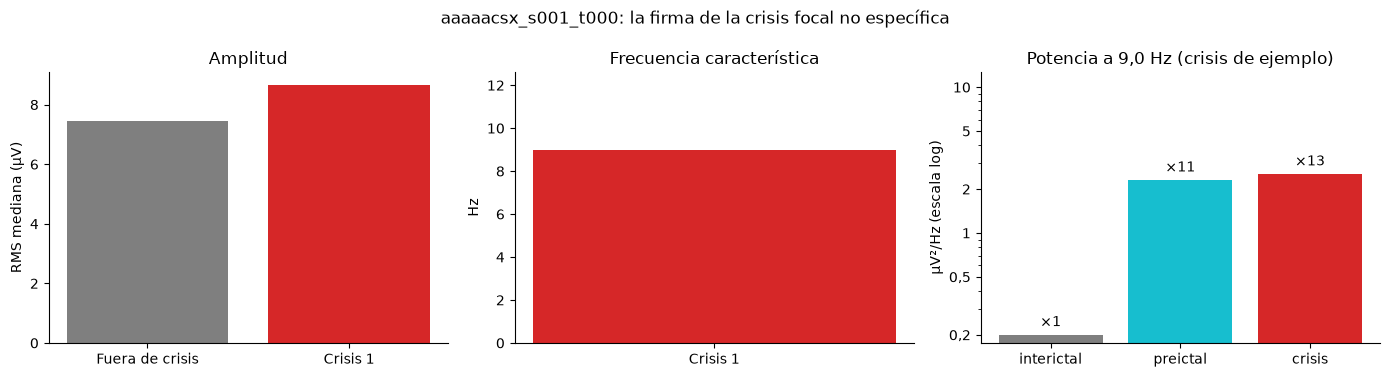

,tipo,frecuencia característica (Hz),RMS (µV)
crisis,,,
Crisis 1,🟥 fnsz (♦️),9.0,8.7


**En este ejemplo** (🟥 fnsz (♦️)):

- Aparece en **5 de 22 canales** TCP: `FP1-F7`, `T5-O1`, `A1-T3`, `T3-C3`, `C3-CZ`.
- La **amplitud** se multiplica por **1,2** (RMS de 9 µV frente a 7 µV fuera de crisis).
- **Frecuencia característica** (el pico que más sobresale del fondo 1/f): 9 Hz (una crisis en el fichero); este tipo no tiene una frecuencia típica única.
- A la frecuencia característica, la potencia de la crisis es **13 veces** la interictal.

**Literatura.** La ILAE clasifica las crisis por su inicio: focal o generalizado [9]. Es el tipo más frecuente de TUSZ con mucha diferencia, así que dominará el entrenamiento. Para un modelo es un reto porque cada paciente tiene su foco: la firma cambia de canales y de forma entre pacientes.

In [29]:
# Las mismas medidas para todas las crisis del fichero
resumen_crisis = []
for i, c in crisis.iterrows():
    f, p = espectro_medio(c.inicio_s, c.fin_s)
    en_c = (t_rms >= c.inicio_s) & (t_rms <= c.fin_s)
    resumen_crisis.append({'crisis': f'Crisis {i + 1}', 'tipo': c.tipo,
                           'frecuencia característica (Hz)': frecuencia_caracteristica(f, p),
                           'RMS (µV)': np.median(rms[en_c])})
resumen_crisis = pd.DataFrame(resumen_crisis).set_index('crisis')
color_tipo = COLORES_ETIQUETA[TIPO_CRISIS]
rango = INFO_TIPO['rango_tipico_hz']

fig, (ax_rms, ax_f, ax_p) = plt.subplots(1, 3, figsize=(14, 3.8))
# Amplitud: fuera de crisis frente a cada crisis
valores_rms = pd.concat([pd.Series({'Fuera de crisis': rms_fuera}), resumen_crisis['RMS (µV)']])
ax_rms.bar(valores_rms.index, valores_rms.values,
           color=[COLORES_PERIODO['interictal']] + [COLORES_ETIQUETA[t] for t in resumen_crisis.tipo])
ax_rms.set_ylabel('RMS mediana (µV)')
ax_rms.set_title('Amplitud')

# Frecuencia característica frente al rango típico del tipo de crisis
if rango:
    ax_f.axhspan(*rango, color=color_tipo, alpha=0.15,
                 label=f'rango típico ({numero_legible(rango[0])}–{rango[1]} Hz)')
ax_f.bar(resumen_crisis.index, resumen_crisis['frecuencia característica (Hz)'],
         color=[COLORES_ETIQUETA[t] for t in resumen_crisis.tipo], width=0.5)
ax_f.set_ylim(0, max(rango[1] if rango else 0, resumen_crisis['frecuencia característica (Hz)'].max()) * 1.4)
ax_f.set_ylabel('Hz')
ax_f.set_title('Frecuencia característica')
if rango:
    ax_f.legend(fontsize=8, loc='upper right')

# Potencia a la frecuencia característica en cada tramo (escala log)
ax_p.bar(list(potencia_pico), list(potencia_pico.values()), color=[colores_tramo[n] for n in potencia_pico])
ax_p.set_yscale('log')
ax_p.set_ylim(top=max(potencia_pico.values()) * 5)          # sitio para las etiquetas ×N
eje_log_legible(ax_p, 'y')
ax_p.set_ylabel('µV²/Hz (escala log)')
ax_p.set_title(f'Potencia a {frec_caracteristica:.1f} Hz (crisis de ejemplo)'.replace('.', ','))
for x_barra, (n, valor) in enumerate(potencia_pico.items()):
    ax_p.text(x_barra, valor * 1.15, f'×{valor / potencia_pico["interictal"]:.0f}', ha='center', fontsize=10)
for ax in (ax_rms, ax_f, ax_p):
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle(f'{EJEMPLO}: la firma de la crisis {INFO_TIPO["nombre"]}')
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'conclusion_2_firma_crisis.png', dpi=150, bbox_inches='tight')
plt.show()
display(tabla_con_iconos(resumen_crisis.round(1), columnas=['tipo']))

texto_rango = (f'{resumen_crisis["frecuencia característica (Hz)"].between(*rango).sum()} de {len(resumen_crisis)} '
               f'dentro del rango típico ({numero_legible(rango[0])}–{rango[1]} Hz)' if rango
               else 'este tipo no tiene una frecuencia típica única')
frecuencias = ' y '.join(numero_legible(f) for f in resumen_crisis['frecuencia característica (Hz)'])
display(Markdown(f'''**En este ejemplo** ({con_icono(TIPO_CRISIS)}):

- Aparece en **{n_canales_crisis} de {len(canales_csv)} canales** TCP{" a la vez (crisis generalizada)" if n_canales_crisis == len(canales_csv) else ": " + ", ".join(f"`{c}`" for c in canales_crisis)}.
- La **amplitud** se multiplica por **{numero_legible(round(rms_crisis / rms_fuera, 1))}** (RMS de {rms_crisis:.0f} µV frente a {rms_fuera:.0f} µV fuera de crisis).
- **Frecuencia característica** (el pico que más sobresale del fondo 1/f): {frecuencias} Hz ({"una crisis en el fichero" if len(resumen_crisis) == 1 else f"{len(resumen_crisis)} crisis en el fichero"}); {texto_rango}.
- A la frecuencia característica, la potencia de la crisis es **{potencia_pico["crisis"] / potencia_pico["interictal"]:.0f} veces** la interictal.

**Literatura.** {INFO_TIPO["literatura"]}'''))

👀 **Cómo leer la figura.** Tres paneles: **amplitud** (barra gris = fuera de crisis, de color = cada crisis del fichero), **frecuencia característica** de cada crisis frente al rango típico del tipo (franja) y **potencia** a esa frecuencia en cada periodo (el ×N es cuántas veces la del interictal). Si todas las crisis del fichero dan valores parecidos, el patrón se repite.

### 15.3. Detectar será más fácil que predecir

- La crisis destaca claramente sobre el fondo. En cambio, entre **preictal** e **interictal** las diferencias son pequeñas, y en otros momentos del fichero, sin crisis detrás, aparecen oscilaciones parecidas.
- **Cuidado con los artefactos.** Si una diferencia entre preictal e interictal se concentra en los canales que **comparten un electrodo**, lo más probable es un mal contacto o movimiento de ese electrodo, no actividad cerebral. Un modelo podría aprender estos "atajos" si no se controlan. Debajo de la figura lo comprobamos automáticamente.
- Con una sola crisis no se puede concluir nada. Si existe una señal preictal, no se ve a simple vista: hace falta un modelo entrenado con muchas crisis y pacientes. Esa es justo la pregunta de la Fase 3.
- **Literatura**: la predicción de crisis lleva décadas abierta. Muchos métodos que parecían funcionar no superaban a un predictor aleatorio cuando se evaluaban con rigor [11]. Los avances recientes (registros largos, aprendizaje profundo) han mejorado los resultados, pero los cambios preictales son sutiles y **muy dependientes de cada paciente** [16]. Por eso la evaluación de la Fase 3 tendrá que compararse con el azar y separar pacientes entre train y test.

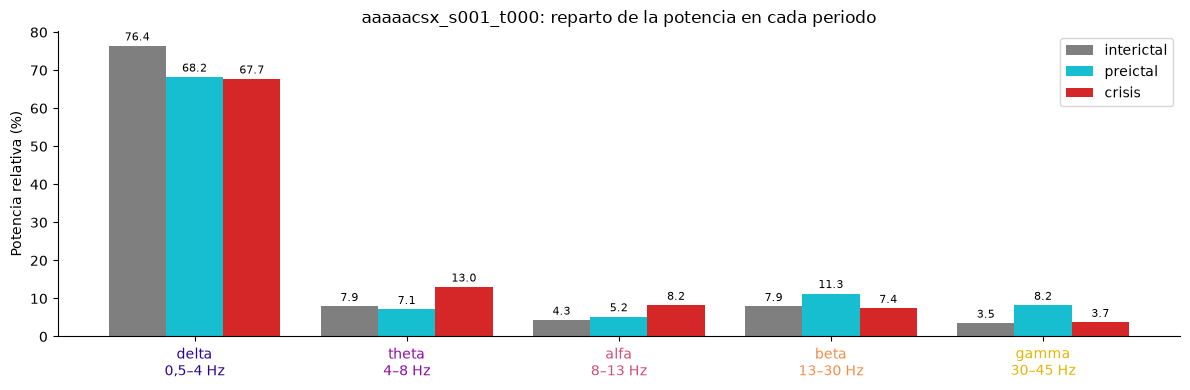

Potencia a 9.0 Hz, preictal / interictal, canales con más aumento:


,veces
T6-O2,32.8
F8-T4,29.1
FP2-F8,24.5
P4-O2,21.1
T4-T6,19.6
F7-T3,17.7


**En este ejemplo:**

- La mayor diferencia de reparto entre preictal e interictal es de **8,2 puntos** (delta).
- A 9 Hz, el tramo preictal tiene **11 veces** la potencia del interictal. El aumento **no se concentra** en un solo electrodo (×13 de media en los 22 canales).

In [30]:
fig, ax = plt.subplots(figsize=(12, 4))
ancho = 0.27
x = np.arange(len(comparacion))
for j, periodo in enumerate(comparacion.columns):
    barras = ax.bar(x + (j - 1) * ancho, comparacion[periodo], ancho, color=colores_tramo[periodo], label=periodo)
    ax.bar_label(barras, fmt='%.1f', fontsize=8, padding=2)
ax.set_xticks(x)
ax.set_xticklabels([f'{b}\n{numero_legible(lo)}–{hi} Hz' for b, (lo, hi) in BANDAS_HZ.items()])
for etiqueta, banda in zip(ax.get_xticklabels(), BANDAS_HZ):
    etiqueta.set_color(COLORES_BANDA[banda])
ax.set_ylabel('Potencia relativa (%)')
ax.set_title(f'{EJEMPLO}: reparto de la potencia en cada periodo')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'conclusion_3_bandas_por_periodo.png', dpi=150, bbox_inches='tight')
plt.show()


def potencia_por_canal(t_ini, t_fin, frecuencia):
    # Potencia de Welch de cada canal TCP a una frecuencia (µV²/Hz)
    tramo_t = (tiempos >= t_ini) & (tiempos < t_fin)
    f, psd = signal.welch(senal_uv[:, tramo_t], fs=FS, nperseg=int(2 * FS))
    return pd.Series(psd[:, np.argmin(np.abs(f - frecuencia))], index=tcp.ch_names)


# Cuánto sube la potencia (preictal / interictal) canal a canal, a la frecuencia característica de la crisis
cociente = (potencia_por_canal(*tramos['preictal'], frec_caracteristica)
            / potencia_por_canal(*tramos['interictal'], frec_caracteristica)).sort_values(ascending=False)
print(f'Potencia a {frec_caracteristica:.1f} Hz, preictal / interictal, canales con más aumento:')
display(cociente.head(6).round(1).rename('veces').to_frame())

# ¿El aumento se concentra en un electrodo? Electrodo que más se repite entre los 4 canales con más aumento
repeticiones = pd.Series([e for canal in cociente.index[:4] for e in canal.split('-')]).value_counts()
sospechoso = repeticiones.index[0]
con_sospechoso = cociente.index.map(lambda canal: sospechoso in canal.split('-'))
media_con, media_sin = cociente[con_sospechoso].mean(), cociente[~con_sospechoso].mean()
artefacto_electrodo = repeticiones.iloc[0] >= 3 and media_con > 3 * media_sin

diferencia_pre = (comparacion.preictal - comparacion.interictal).abs()
texto_artefacto = (
    f'El aumento se concentra en los canales que comparten el electrodo **`{sospechoso}`** '
    f'(×{media_con:.0f} de media, frente a ×{media_sin:.0f} en el resto): muy probablemente es un '
    f'**artefacto de ese electrodo**, no actividad cerebral.' if artefacto_electrodo else
    f'El aumento **no se concentra** en un solo electrodo (×{cociente.mean():.0f} de media en los '
    f'{len(cociente)} canales).')
display(Markdown(f'''**En este ejemplo:**

- La mayor diferencia de reparto entre preictal e interictal es de **{numero_legible(diferencia_pre.max())} puntos** ({diferencia_pre.idxmax()}).
- A {numero_legible(frec_caracteristica)} Hz, el tramo preictal tiene **{potencia_pico["preictal"] / potencia_pico["interictal"]:.0f} veces** la potencia del interictal. {texto_artefacto}'''))

### 15.4. El lead-in en un caso real

- El umbral de lead-in se aplica **crisis a crisis**, no fichero a fichero: en un mismo fichero puede haber crisis que sirven para predicción y crisis que no. Cada crisis usa el **umbral de su tipo** y se le descuenta el **margen postictal** de la anterior (`tfm_comun/prediccion/umbrales.py`); el margen se dibuja en malva.
- **Literatura**: los estudios de predicción suelen quedarse solo con las crisis que van precedidas de un intervalo libre (*leading seizures*), porque las crisis en racimo comparten el mismo periodo preictal y "inflarían" los resultados [11, 15]. En registros largos se exigen intervalos de horas; en TUSZ, con ficheros de minutos, trabajamos con umbrales cortos (4 min, y 60 s en las ausencias).

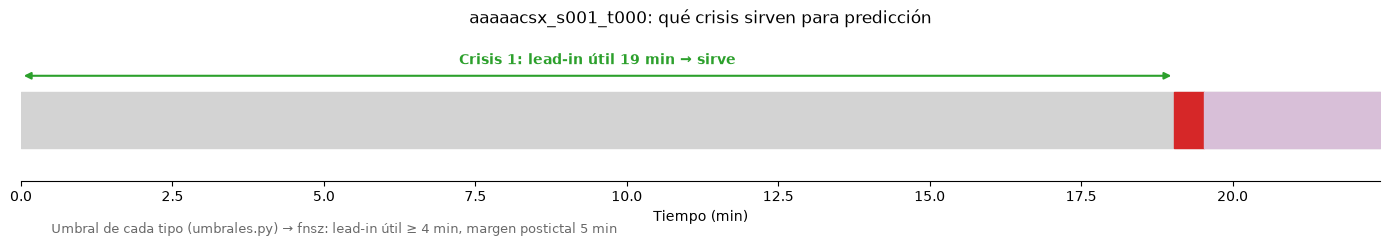

**En este ejemplo:**

- Crisis 1 (🟥 fnsz (♦️)): lead-in útil de **19 min** (umbral 4 min) → ✅ sirve para predicción

In [31]:
fig, ax = plt.subplots(figsize=(14, 2.8))
ax.broken_barh([(0, tiempos[-1] / 60)], (0, 1), color=COLORES_ETIQUETA['bckg'])
inicio_libre = 0
for i, c in crisis.iterrows():
    sirve = c.leadin_util_s >= umbral_leadin_s(c.tipo)
    ax.broken_barh([(c.inicio_s / 60, c.duracion_s / 60)], (0, 1), color=COLORES_ETIQUETA[c.tipo])
    if margen_postictal_s(c.tipo):
        ax.broken_barh([(c.fin_s / 60, min(margen_postictal_s(c.tipo), tiempos[-1] - c.fin_s) / 60)], (0, 1),
                       color=COLORES_PERIODO['postictal'])
    color = 'tab:green' if sirve else 'tab:red'
    ax.annotate('', xy=(c.inicio_s / 60, 1.3), xytext=(inicio_libre / 60, 1.3),
                arrowprops=dict(arrowstyle='<|-|>', color=color, linewidth=1.5))
    ax.text((inicio_libre + c.inicio_s) / 2 / 60, 1.45,
            f'Crisis {i + 1}: lead-in útil {duracion_legible(c.leadin_util_s)} → {"sirve" if sirve else "no sirve"}',
            ha='center', va='bottom', fontsize=10, color=color, fontweight='bold')
    inicio_libre = c.fin_s + margen_postictal_s(c.tipo)
umbrales = ' | '.join(f'{t}: lead-in útil ≥ {duracion_legible(umbral_leadin_s(t))}, margen postictal '
                      f'{duracion_legible(margen_postictal_s(t))}' for t in crisis.tipo.unique())
ax.text(0.5, -0.35, f'Umbral de cada tipo (umbrales.py) → {umbrales}', fontsize=9, color='dimgray',
        transform=ax.get_xaxis_transform())
ax.set_xlim(0, tiempos[-1] / 60)
ax.set_ylim(-0.6, 2.1)
ax.set_yticks([])
ax.set_xlabel('Tiempo (min)')
ax.set_title(f'{EJEMPLO}: qué crisis sirven para predicción')
ax.spines[['top', 'right', 'left']].set_visible(False)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'conclusion_4_leadin.png', dpi=150, bbox_inches='tight')
plt.show()

lineas = [f'- Crisis {i + 1} ({con_icono(c.tipo)}): lead-in útil de **{duracion_legible(c.leadin_util_s)}** '
          f'(umbral {duracion_legible(umbral_leadin_s(c.tipo))}) → '
          f'{"✅ sirve" if c.leadin_util_s >= umbral_leadin_s(c.tipo) else "❌ no sirve"} para predicción'
          for i, c in crisis.iterrows()]
display(Markdown('**En este ejemplo:**\n\n' + '\n'.join(lineas)))

### 15.5. Implicaciones para la Fase 2

- El filtrado 0,5–40 Hz + notch 60 Hz **conserva la firma** de la crisis (sección 8). Para las bandas, gamma necesita llegar a 45 Hz.
- La **duración** de las crisis cambia mucho entre tipos (figura): con crisis cortas hacen falta **ventanas cortas** (2–4 s), o una ventana larga se llenaría de señal normal.
- La amplitud cambia mucho entre crisis y fondo, y entre pacientes: habrá que **normalizar** la señal (por canal o por fichero) antes de dar las ventanas a la red.
- Los **artefactos** (parpadeos en `FP1`/`FP2`, músculo, movimiento, electrodos sueltos) aparecen en todos los ficheros. El modelo los verá, así que conviene medirlos y, si hace falta, limpiarlos (por ejemplo con ICA).
- **Literatura**: en los trabajos de aprendizaje profundo con EEG, las ventanas de pocos segundos y la normalización por canal son la práctica habitual [17]. Los artefactos oculares y musculares son una fuente importante de falsos positivos en detección automática [14].

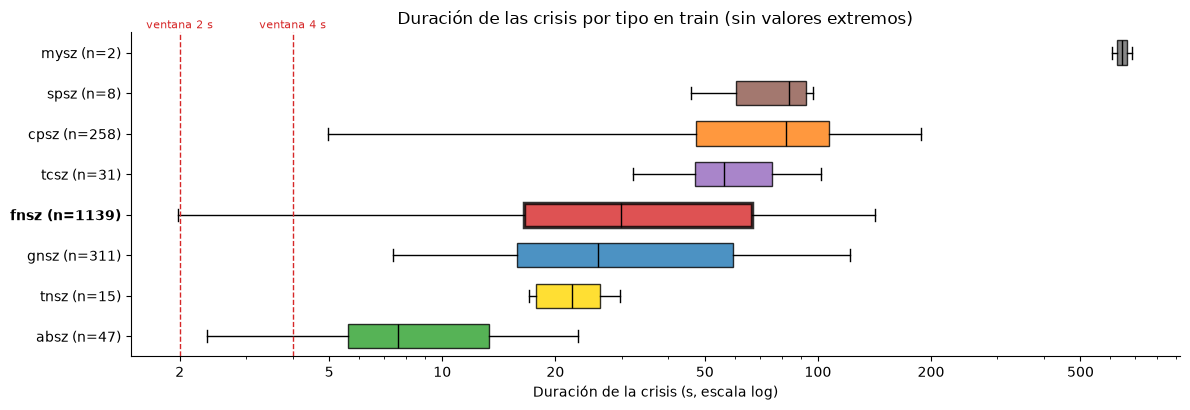

**En este ejemplo** (🟥 fnsz (♦️) en 🔵 train):

- **1139 crisis** de **101 pacientes**, con una duración mediana de **30,0 s**: es el tipo nº 4 más corto de 8.
- El **9 %** dura menos de 10 s.
- Artefacto en el fichero de ejemplo: 🔴 **0 %** del registro (0,083 min). Habrá que detectar y descartar estos tramos antes de construir ventanas.

In [32]:
crisis_train = df_crisis[(df_crisis.split == 'train') & (df_crisis.label != 'sin_tipo')]
orden = crisis_train.groupby('label').dur_s.median().sort_values().index
# 'orientation' existe desde matplotlib 3.10; en versiones anteriores se usaba vert=False
horizontal = ({'orientation': 'horizontal'} if tuple(map(int, matplotlib.__version__.split('.')[:2])) >= (3, 10)
              else {'vert': False})
fig, ax = plt.subplots(figsize=(12, 4.2))
cajas = ax.boxplot([crisis_train.loc[crisis_train.label == t, 'dur_s'] for t in orden], patch_artist=True,
                   widths=0.6, showfliers=False, **horizontal)
for caja, tipo in zip(cajas['boxes'], orden):
    caja.set_facecolor(COLORES_ETIQUETA[tipo])
    caja.set_alpha(0.8)
    caja.set_linewidth(2.5 if tipo == TIPO_CRISIS else 1)         # resalta el tipo de este notebook
for mediana in cajas['medians']:
    mediana.set_color('black')
ax.set_yticks(range(1, len(orden) + 1))
ax.set_yticklabels([f'{t} (n={(crisis_train.label == t).sum()})' for t in orden])
for etiqueta, tipo in zip(ax.get_yticklabels(), orden):
    etiqueta.set_fontweight('bold' if tipo == TIPO_CRISIS else 'normal')
for segundos in (2, 4):
    ax.axvline(segundos, color='tab:red', linestyle='--', linewidth=1)
    ax.text(segundos, len(orden) + 0.6, f'ventana {segundos} s', color='tab:red', ha='center', fontsize=8)
ax.set_xscale('log')
eje_log_legible(ax, 'x')
ax.set_xlabel('Duración de la crisis (s, escala log)')
ax.set_title('Duración de las crisis por tipo en train (sin valores extremos)')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'conclusion_5_duracion_por_tipo.png', dpi=150, bbox_inches='tight')
plt.show()

dur_tipo = crisis_train.loc[crisis_train.label == TIPO_CRISIS, 'dur_s']
puesto = list(orden).index(TIPO_CRISIS) + 1
pacientes = crisis_train.loc[crisis_train.label == TIPO_CRISIS, 'patient'].nunique()
display(Markdown(f'''**En este ejemplo** ({con_icono(TIPO_CRISIS)} en {con_icono("train")}):

- **{len(dur_tipo)} crisis** de **{pacientes} pacientes**, con una duración mediana de **{numero_legible(dur_tipo.median())} s**: es el tipo nº {puesto} más corto de {len(orden)}.
- El **{(dur_tipo < 10).mean() * 100:.0f} %** dura menos de 10 s.
- Artefacto en el fichero de ejemplo: {f"🔴 **{artefacto.mean() * 100:.0f} %** del registro ({numero_legible(artefacto.sum() / 60)} min). Habrá que detectar y descartar estos tramos antes de construir ventanas." if artefacto.any() else "sin tramos evidentes."}'''))

👀 **Cómo leer la figura.** Una caja por tipo con la duración de sus crisis en 🔵 train (eje logarítmico; la caja del tipo de este notebook va con borde grueso). Las líneas rojas son ventanas de 2 y 4 s: los tipos cuya caja queda cerca de ellas (las ausencias) tienen crisis que apenas llenan una o dos ventanas.

## 16. Bibliografía

1. Shah V, von Weltin E, Lopez S, McHugh JR, Veloso L, Golmohammadi M, Obeid I, Picone J. *The Temple University Hospital Seizure Detection Corpus*. Frontiers in Neuroinformatics, 12:83, 2018.
2. Obeid I, Picone J. *The Temple University Hospital EEG Data Corpus*. Frontiers in Neuroscience, 10:196, 2016.
3. Jasper HH. *The ten-twenty electrode system of the International Federation*. Electroencephalography and Clinical Neurophysiology, 10:371–375, 1958.
4. Acharya JN, Hani AJ, Cheek J, Thirumala P, Tsuchida TN. *American Clinical Neurophysiology Society Guideline 2: Guidelines for Standard Electrode Position Nomenclature*. Journal of Clinical Neurophysiology, 33(4):308–311, 2016.
5. Lopez S, Gross A, Yang S, Golmohammadi M, Obeid I, Picone J. *An Analysis of Two Common Reference Points for EEGs*. IEEE Signal Processing in Medicine and Biology Symposium (SPMB), 2016.
6. Ferrell S, Mathew V, Refford M, Tchiong V, Ahsan T, Obeid I, Picone J. *The Temple University Hospital EEG Corpus: Electrode Location and Channel Labels*. Informe técnico, Temple University, 2020 (en `DOCS/` de TUSZ).
7. Welch PD. *The use of fast Fourier transform for the estimation of power spectra: a method based on time averaging over short, modified periodograms*. IEEE Transactions on Audio and Electroacoustics, 15(2):70–73, 1967.
8. Gramfort A, et al. *MEG and EEG data analysis with MNE-Python*. Frontiers in Neuroscience, 7:267, 2013.
9. Fisher RS, et al. *Operational classification of seizure types by the International League Against Epilepsy*. Epilepsia, 58(4):522–530, 2017.
10. Sadleir LG, Farrell K, Smith S, Connolly MB, Scheffer IE. *Electroclinical features of absence seizures in childhood absence epilepsy*. Neurology, 67(3):413–418, 2006.
11. Mormann F, Andrzejak RG, Elger CE, Lehnertz K. *Seizure prediction: the long and winding road*. Brain, 130(2):314–333, 2007.
12. Blumenfeld H. *Cellular and network mechanisms of spike-wave seizures*. Epilepsia, 46(Suppl 9):21–33, 2005.
13. Crunelli V, Leresche N. *Childhood absence epilepsy: genes, channels, neurons and networks*. Nature Reviews Neuroscience, 3(5):371–382, 2002.
14. Muthukumaraswamy SD. *High-frequency brain activity and muscle artifacts in MEG/EEG: a review and recommendations*. Frontiers in Human Neuroscience, 7:138, 2013.
15. Winterhalder M, Maiwald T, Voss HU, Aschenbrenner-Scheibe R, Timmer J, Schulze-Bonhage A. *The seizure prediction characteristic: a general framework to assess and compare seizure prediction methods*. Epilepsy & Behavior, 4(3):318–325, 2003.
16. Kuhlmann L, Lehnertz K, Richardson MP, Schelter B, Zaveri HP. *Seizure prediction — ready for a new era*. Nature Reviews Neurology, 14(10):618–630, 2018.
17. Roy Y, Banville H, Albuquerque I, Gramfort A, Falk TH, Faubert J. *Deep learning-based electroencephalography analysis: a systematic review*. Journal of Neural Engineering, 16(5):051001, 2019.
18. Arzimanoglou A, French J, Blume WT, Cross JH, Ernst JP, Feucht M, et al. *Lennox-Gastaut syndrome: a consensus approach on diagnosis, assessment, management, and trial methodology*. The Lancet Neurology, 8(1):82–93, 2009.
19. Devinsky O, Kelley K, Porter RJ, Theodore WH. *Clinical and electroencephalographic features of simple partial seizures*. Neurology, 38(9):1347–1352, 1988.
20. Donoghue T, Haller M, Peterson EJ, Varma P, Sebastian P, Gao R, et al. *Parameterizing neural power spectra into periodic and aperiodic components*. Nature Neuroscience, 23(12):1655–1665, 2020.
21. Pascual-Marqui RD. *Standardized low-resolution brain electromagnetic tomography (sLORETA): technical details*. Methods and Findings in Experimental and Clinical Pharmacology, 24(Suppl D):5–12, 2002.
22. Fischl B, Sereno MI, Tootell RBH, Dale AM. *High-resolution intersubject averaging and a coordinate system for the cortical surface*. Human Brain Mapping, 8(4):272–284, 1999.
23. Desikan RS, Ségonne F, Fischl B, Quinn BT, Dickerson BC, Blacker D, et al. *An automated labeling system for subdividing the human cerebral cortex on MRI scans into gyral based regions of interest*. NeuroImage, 31(3):968–980, 2006.
24. Michel CM, Murray MM, Lantz G, Gonzalez S, Spinelli L, Grave de Peralta R. *EEG source imaging*. Clinical Neurophysiology, 115(10):2195–2222, 2004.
25. Lantz G, Grave de Peralta R, Spinelli L, Seeck M, Michel CM. *Epileptic source localization with high density EEG: how many electrodes are needed?* Clinical Neurophysiology, 114(1):63–69, 2003.
26. Bartolomei F, Chauvel P, Wendling F. *Epileptogenicity of brain structures in human temporal lobe epilepsy: a quantified study from intracerebral EEG*. Brain, 131(7):1818–1830, 2008.

## 17. Archivos generados

En `outputs/fase_01/03_visualizacion/<tipo>/` (una carpeta por tipo de crisis):

- `configuracion.json`: tipo, fichero de ejemplo, periodos, filtros, bandas, versiones de las librerías y fecha.
- `crisis_ejemplo.csv`: crisis del fichero de ejemplo (inicio, fin, tipo, duración, lead-in).
- `origen_por_lobulo.csv`: cuánto crece la potencia al inicio de la crisis en cada lóbulo y hemisferio (sección 14).
- `figuras/`: todas las figuras del notebook, en el orden en que aparecen.

In [33]:
crisis.round(3).to_csv(RUTA_RESULTADOS / 'crisis_ejemplo.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'crisis_ejemplo.csv',
                'las crisis del fichero de ejemplo: inicio, fin, duración y tipo')
for f in sorted(RUTA_RESULTADOS.rglob('*.*'), key=lambda f: f.stat().st_mtime):
    print(f.relative_to(RUTA_RESULTADOS))

💾 **Guardado `crisis_ejemplo.csv`** · 104 B · 1 filas × 6 columnas  
*Qué guarda:* las crisis del fichero de ejemplo: inicio, fin, duración y tipo. *Abajo:* las 1 primeras filas.

,inicio_s,fin_s,tipo,duracion_s,leadin_s,leadin_util_s
0,1142.072,1172.067,🟥 fnsz (♦️),29.995,1142.072,1142.072


figuras\esquema_periodos.png
figuras\sistema_10_20.png
figuras\anotaciones_linea_tiempo.png
figuras\montaje_tcp.png
figuras\espectro_antes_despues_filtro.png
figuras\ondas_por_banda.png
figuras\mapa_fichero.png
figuras\crisis_22_canales.png
figuras\zoom_y_espectro.png
figuras\espectrograma_crisis.png
figuras\potencia_por_bandas.png
figuras\origen_1_arranque_canales.png
configuracion.json
origen_por_lobulo.csv
figuras\origen_2_vista_desde_arriba.png
figuras\origen_3_cerebro_3d.png
figuras\conclusion_1_del_edf_al_tcp.png
figuras\conclusion_2_firma_crisis.png
figuras\conclusion_3_bandas_por_periodo.png
figuras\conclusion_4_leadin.png
figuras\conclusion_5_duracion_por_tipo.png
03v_visualizacion_fnsz_focal_no_especifica.ipynb
crisis_ejemplo.csv
